# Back-four defence in negative transitions: final pipeline

Run the cells **in order**. Every cell ends with a **CHECK** block that prints `OK` or `PROBLEM`, plus the value from the last full run where one exists. Send me any `PROBLEM` line or any number that differs.

| Part | Cells | What |
|---|---|---|
| A. Preprocessing | A1-A11 | data → one row per sequence → analysis sample |
| B. Analysis | B1-B6 | ANOVA, Table 3, models, SHAP, robustness checks |

Cells A3-A9 work on **one match** (`DEBUG_MATCH`) so each step can be checked. A10 runs all matches.

## A1. Imports and settings
The only place settings live. Nothing else in the notebook changes them, except B6, which switches the feature window for one sensitivity run and switches it back.

In [2]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull, QhullError
from tqdm import tqdm
from IPython.display import display
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option('display.width', 160)

# ---- paths ----
DATA_DIR = "/home/s_dash/workspace7/Defense_line_analysis/Defense_line/Barcelona_tracking_excels"
OUT_DIR  = os.path.join(DATA_DIR, "combined_outputs")
OUT_CSV  = os.path.join(OUT_DIR, "features_corrected.csv")

# ---- sequence ----
SEQ_LEN = 10                  # events after the turnover (Methods). A sequence stopped earlier by a
                              # stoppage is kept ONLY if it had already failed (outcome known)
EXCLUDE_LOSS_IN_BOX = True    # a loss inside our own box is a failure before any defending: dropped

# ---- frames used for the features ----
FEATURE_ANCHOR      = "events"   # MAIN: +/- FEATURE_HALF_WINDOW frames around the LOSS and each of the 10 events
                                 # "loss": the FEATURE_PRE_FRAMES frames up to the loss (cell B6 only)
# Tracking is 10 Hz (0.1 s per frame), NOT 25 Hz.
FEATURE_HALF_WINDOW = 12         # 12 frames = 1.2 s each side -> the 2.4 s window in the Methods
FEATURE_PRE_FRAMES  = 12         # 1.2 s before the loss (B6 only)
# The window always ENDS at the end of the defending phase (A9):
#   failure -> the first box entry or shot | success -> the 10th event, or an earlier regain of possession
FRAME_STEP          = 1

# ---- feature constants (Methods, Eq. 1-5, Table 1) ----
LAMBDA      = 0.5     # Eq. 1 weight; stretch = 0.5 * hull area + 0.5 * PDA (as in the manuscript)
PRESS_R     = 3.0     # Eq. 2 radius (m)
SPACE_EPS   = 1.0     # Eq. 3 epsilon
BALL_RADIUS = 3.0     # ball zone radius (m), as in Fig. 1 and the original code; Table 1 must say 3 m

# ---- analysis ----
OWN_HALF_X  = 52.5    # analysis sample: ball reached x <= 52.5 within the 10 events
DEF_THIRD_X = 35.0    # recorded for description only
TEAMS = ['Barcelona', 'Real Madrid']
FEATURES = ['line_height_rel_ball_mean', 'line_height_abs_mean', 'stretch_index_mean',
            'pressure_index_mean', 'space_score_mean']
NICE = {'line_height_rel_ball_mean': 'Line height (relative)', 'line_height_abs_mean': 'Line height (absolute)',
        'stretch_index_mean': 'Stretch index', 'pressure_index_mean': 'Pressure index',
        'space_score_mean': 'Space score'}
SEED = 42

# ---- CHECK ----
print("DATA_DIR exists:", 'OK' if os.path.isdir(DATA_DIR) else 'PROBLEM')
print(f"feature window: {FEATURE_ANCHOR}, +/-{FEATURE_HALF_WINDOW} frames | sequence: {SEQ_LEN} events | ball radius {BALL_RADIUS} m")

DATA_DIR exists: OK
feature window: events, +/-12 frames | sequence: 10 events | ball radius 3.0 m


## A2. Pitch, names, event vocabularies, plot helper

In [3]:
FIELD_L, FIELD_W = 105.0, 68.0
BOX_DEPTH = 16.5
BOX_Y_MIN = (FIELD_W - 40.32) / 2     # 13.84
BOX_Y_MAX = (FIELD_W + 40.32) / 2     # 54.16

TEAM_NAMES = {   # SkillCorner name -> StatsBomb name
    'UD Almería': 'Almería', 'Real Sociedad': 'Real Sociedad', 'Athletic Club de Bilbao': 'Athletic Club',
    'Villarreal CF': 'Villarreal', 'RC Celta de Vigo': 'Celta Vigo', 'Getafe CF': 'Getafe',
    'UD Las Palmas': 'Las Palmas', 'Sevilla FC': 'Sevilla', 'Cadiz CF': 'Cádiz',
    'Atlético Madrid': 'Atlético Madrid', 'RCD Mallorca': 'Mallorca', 'Valencia CF': 'Valencia',
    'CA Osasuna': 'Osasuna', 'Girona FC': 'Girona', 'Real Betis Balompié': 'Real Betis',
    'FC Barcelona': 'Barcelona', 'Deportivo Alavés': 'Deportivo Alavés', 'Granada CF': 'Granada',
    'Rayo Vallecano': 'Rayo Vallecano', 'Real Madrid CF': 'Real Madrid'}

# Not possession actions: ignored when looking for a change of possession.
NON_POSSESSION = {'Starting XI', 'Half Start', 'Half End', 'Tactical Shift', 'Substitution',
                  '50/50', 'Offside', 'Foul Committed', 'Foul Won', 'Injury Stoppage',
                  'Referee Ball-Drop', 'Error'}
# Stoppages: a sequence that meets one of these before 10 events is dropped.
RESTART_TYPE = {'Substitution', 'Half Start', 'Half End', 'Offside', 'Foul Committed',
                'Foul Won', 'Injury Stoppage', 'Referee Ball-Drop'}
# Set pieces live in `event_type_2`. The tag can be glued to another flag
# (e.g. 'TrueFree Kick'), so we test whether the tag CONTAINS a set-piece name.
RESTART_TYPE2 = ('Goal Kick', 'Throw-in', 'Free Kick', 'Corner', 'Kick Off')

def is_set_piece_tag(tag):
    """True if an event_type_2 value is (or contains) a set-piece name."""
    s = str(tag)
    return any(k in s for k in RESTART_TYPE2)

def draw_frame(ax, D, A, ball, title=''):
    """Normalized frame: own goal on the LEFT (x = 0)."""
    ax.add_patch(plt.Rectangle((0, 0), FIELD_L, FIELD_W, fill=False, color='0.6'))
    ax.add_patch(plt.Rectangle((0, BOX_Y_MIN), BOX_DEPTH, BOX_Y_MAX - BOX_Y_MIN, fill=False, color='0.6'))
    ax.axvline(FIELD_L / 2, color='0.85', lw=0.8)
    B4 = D[np.argsort(D[:, 0])[:4]]
    A3 = A[np.argsort(A[:, 0])[:3]]
    ax.scatter(D[:, 0], D[:, 1], c='lightsteelblue', s=25, label='defending team')
    ax.scatter(B4[:, 0], B4[:, 1], c='tab:blue', s=70, label='back four')
    ax.scatter(A[:, 0], A[:, 1], c='mistyrose', edgecolor='tab:red', s=25, label='attacking team')
    ax.scatter(A3[:, 0], A3[:, 1], c='tab:red', s=70, label='3 nearest attackers')
    ax.scatter(*ball, marker='*', c='gold', edgecolor='k', s=200, label='ball', zorder=5)
    ax.set_xlim(-2, 107); ax.set_ylim(-2, 70); ax.set_aspect('equal')
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])

print("CHECK: box y range", round(BOX_Y_MIN, 2), "-", round(BOX_Y_MAX, 2), "(expected 13.84 - 54.16)",
      'OK' if abs(BOX_Y_MIN - 13.84) < 0.01 else 'PROBLEM')
print("CHECK: 'TrueFree Kick' read as a set piece:", 'OK' if is_set_piece_tag('TrueFree Kick') else 'PROBLEM',
      "| 'Recovery' not a set piece:", 'OK' if not is_set_piece_tag('Recovery') else 'PROBLEM')

CHECK: box y range 13.84 - 54.16 (expected 13.84 - 54.16) OK
CHECK: 'TrueFree Kick' read as a set piece: OK | 'Recovery' not a set piece: OK


## A3. STEP 1: load one match, build the tracking arrays
Tracking is shifted from centre origin to 0-105 x 0-68. Every goalkeeper is remembered (substitutes too), so all of them can be excluded from the back four later.

In [4]:
def list_matches():
    return sorted(d for d in os.listdir(DATA_DIR)
                  if os.path.isdir(os.path.join(DATA_DIR, d)) and d != "combined_outputs")

def load_match(match_dir):
    """(events, tracking, match), or None if a file is missing."""
    path = os.path.join(DATA_DIR, match_dir)
    files = [os.path.join(path, f) for f in ('events.csv', 'tracking.json', 'match.json')]
    if not all(os.path.exists(p) for p in files):
        return None
    events = pd.read_csv(files[0])
    with open(files[1]) as fh:
        tracking = json.load(fh)
    with open(files[2], encoding='utf-8') as fh:
        match = json.load(fh)
    return events, tracking, match

def build_tracking(tracking, match):
    """Raw frames -> arrays indexed by frame number. Player slot k = k-th player of that team in match.json."""
    home_id = match['home_team']['id']
    slot, gk, count = {}, {'h': [], 'a': []}, {'h': 0, 'a': 0}
    for p in match['players']:
        side = 'h' if p['team_id'] == home_id else 'a'
        k = count[side]
        if k >= 23:
            continue
        count[side] += 1
        slot[p['trackable_object']] = (side, k)
        if p['player_role']['name'] == 'Goalkeeper':
            gk[side].append(k)
    ball_obj = match['ball']['trackable_object']

    frames, periods, rows_h, rows_a, rows_b = [], [], [], [], []
    for fr in tracking:
        if fr.get('period') is None or fr.get('frame') is None or not fr.get('data'):
            continue
        h, a, b = np.full((23, 2), np.nan), np.full((23, 2), np.nan), np.full(2, np.nan)
        for o in fr['data']:
            x, y = o['x'] + FIELD_L / 2, -o['y'] + FIELD_W / 2
            if o['trackable_object'] == ball_obj:
                b[:] = (x, y)
            elif o['trackable_object'] in slot:
                side, k = slot[o['trackable_object']]
                (h if side == 'h' else a)[k] = (x, y)
        frames.append(int(fr['frame'])); periods.append(int(fr['period']))
        rows_h.append(h); rows_a.append(a); rows_b.append(b)

    frames = np.array(frames)
    order = np.argsort(frames)
    trk = {'frame': frames[order], 'period': np.array(periods)[order],
           'h': np.stack(rows_h)[order], 'a': np.stack(rows_a)[order],
           'ball': np.stack(rows_b)[order], 'gk': gk}
    trk['row_of'] = {f: i for i, f in enumerate(trk['frame'])}
    return trk

# ---------------- CHECK on one match ----------------
dirs = list_matches()
print(f"match folders: {len(dirs)}   (last run: 74 = 73 matches + the empty 'sorry' folder)")
DEBUG_MATCH = dirs[0]                      # <- change to any folder name
events, tracking, match = load_match(DEBUG_MATCH)
home = TEAM_NAMES[match['home_team']['name']]
away = TEAM_NAMES[match['away_team']['name']]
trk = build_tracking(tracking, match)
has_ball = ~np.isnan(trk['ball']).any(axis=1)
print(f"{DEBUG_MATCH}: {home} (home) v {away} (away)")
print(f"frames with player data: {len(trk['frame']):,} of {len(tracking):,} | frames with ball: {has_ball.mean():.0%}")
print("periods (frames):", {int(k): int(v) for k, v in zip(*np.unique(trk['period'], return_counts=True))})
gk_list = [(('home' if p['team_id'] == match['home_team']['id'] else 'away'), p.get('short_name'))
           for p in match['players'] if p['player_role']['name'] == 'Goalkeeper']
print("goalkeepers found:", gk_list)
print("pitch:", match.get('pitch_length'), "x", match.get('pitch_width'), "(assumed 105 x 68)")
print("CHECK: at least one keeper per team:",
      'OK' if trk['gk']['h'] and trk['gk']['a'] else 'PROBLEM')
print("CHECK: frame numbers strictly increasing:",
      'OK' if (np.diff(trk['frame']) > 0).all() else 'PROBLEM')

match folders: 74   (last run: 74 = 73 matches + the empty 'sorry' folder)
1021404: Athletic Club (home) v Real Madrid (away)
frames with player data: 45,888 of 59,571 | frames with ball: 100%
periods (frames): {1: 23179, 2: 22709}
goalkeepers found: [('away', 'A. Lunin'), ('home', 'Unai Simón')]
pitch: 105 x 68 (assumed 105 x 68)
CHECK: at least one keeper per team: OK
CHECK: frame numbers strictly increasing: OK


## A4. STEP 2: which goal each team defends, and normalization
For every sequence, the team that **lost** the ball is the defending team and is mirrored (players and ball together, once) so it defends **x = 0**. The opponent then attacks from right to left.

home team defends raw x = 0 in period: {1: True, 2: False}
CHECK: ends swap at half time: OK


,defending team,period,flip?,"own GK median x, raw","own GK median x, normalized"
0,Athletic Club,1,False,12.5,12.5
1,Athletic Club,2,True,88.8,16.2
2,Real Madrid,1,True,91.5,13.5
3,Real Madrid,2,False,8.3,8.3


CHECK: after normalization each team's own keeper sits near x = 0: OK


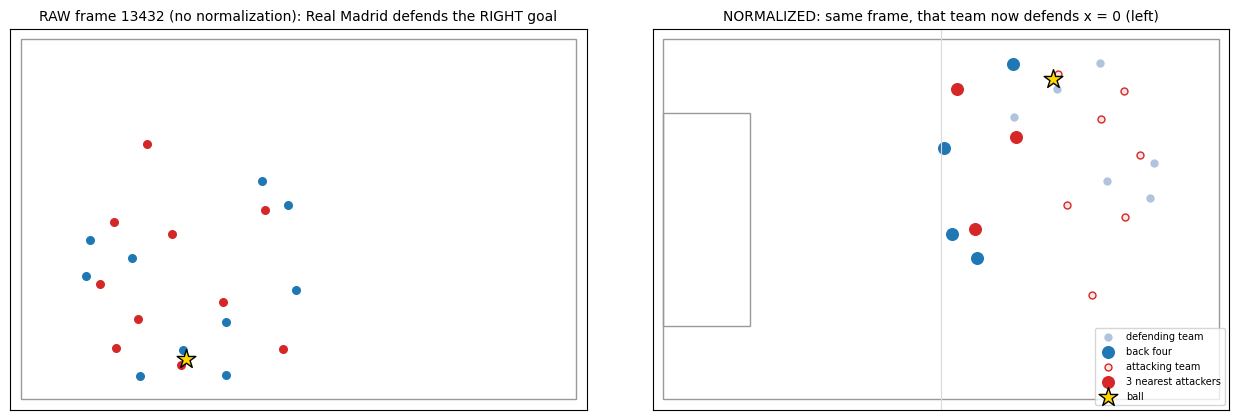

In [5]:
def home_defends_left(trk):
    """{period: True if the HOME team defends raw x = 0}. From each team's goalkeepers' median x."""
    out = {}
    for per in np.unique(trk['period']):
        m = trk['period'] == per
        hx = trk['h'][m][:, trk['gk']['h'], 0] if trk['gk']['h'] else np.array([np.nan])
        ax = trk['a'][m][:, trk['gk']['a'], 0] if trk['gk']['a'] else np.array([np.nan])
        out[int(per)] = bool(np.nanmedian(hx) < np.nanmedian(ax))
    return out

def needs_flip(def_side, period, hdl):
    defends_left = hdl[period] if def_side == 'h' else not hdl[period]
    return not defends_left

def normalize_points(pts, flip):
    """THE ONLY place coordinates are mirrored."""
    if not flip:
        return pts
    out = pts.copy()
    out[..., 0] = FIELD_L - out[..., 0]
    out[..., 1] = FIELD_W - out[..., 1]
    return out

def frame_state(trk, frame, def_side, period, hdl):
    """Normalized (D outfield, A outfield, ball) at one frame, or None if frame/ball missing."""
    i = trk['row_of'].get(int(frame))
    if i is None or trk['period'][i] != period or np.isnan(trk['ball'][i]).any():
        return None
    flip = needs_flip(def_side, period, hdl)
    att_side = 'a' if def_side == 'h' else 'h'
    def outfield(side):
        P = trk[side][i]
        keep = np.ones(23, dtype=bool)
        keep[trk['gk'][side]] = False                  # every keeper, subs included
        P = P[keep]
        return P[~np.isnan(P).any(axis=1)]
    D = normalize_points(outfield(def_side), flip)
    A = normalize_points(outfield(att_side), flip)
    ball = normalize_points(trk['ball'][i][None, :], flip)[0]
    return D, A, ball

# ---------------- CHECK ----------------
hdl = home_defends_left(trk)
print("home team defends raw x = 0 in period:", hdl)
print("CHECK: ends swap at half time:", 'OK' if hdl.get(1) != hdl.get(2) else 'PROBLEM')
rows = []
for side, name in (('h', home), ('a', away)):
    for per in sorted(hdl):
        G = trk[side][trk['period'] == per][:, trk['gk'][side], :].reshape(-1, 2)
        G = G[~np.isnan(G).any(axis=1)]
        Gn = normalize_points(G, needs_flip(side, per, hdl))
        rows.append({'defending team': name, 'period': per, 'flip?': needs_flip(side, per, hdl),
                     'own GK median x, raw': round(float(np.median(G[:, 0])), 1),
                     'own GK median x, normalized': round(float(np.median(Gn[:, 0])), 1)})
chk = pd.DataFrame(rows)
display(chk)
print("CHECK: after normalization each team's own keeper sits near x = 0:",
      'OK' if (chk['own GK median x, normalized'] < 30).all() else 'PROBLEM')

# picture: one frame of period 1, raw vs normalized, for the team that needs the flip
side = 'h' if needs_flip('h', 1, hdl) else 'a'
p1 = np.flatnonzero((trk['period'] == 1) & has_ball)
f_demo = int(trk['frame'][p1[len(p1) // 2]])
i = trk['row_of'][f_demo]
keep = lambda s: np.delete(trk[s][i], trk['gk'][s], axis=0)
raw_D, raw_A = keep(side), keep('a' if side == 'h' else 'h')
raw_D, raw_A = raw_D[~np.isnan(raw_D).any(1)], raw_A[~np.isnan(raw_A).any(1)]
D, A, ball = frame_state(trk, f_demo, side, 1, hdl)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
axs[0].scatter(raw_D[:, 0], raw_D[:, 1], c='tab:blue', s=30, label='defending team')
axs[0].scatter(raw_A[:, 0], raw_A[:, 1], c='tab:red', s=30, label='attacking team')
axs[0].scatter(*trk['ball'][i], marker='*', c='gold', edgecolor='k', s=200, label='ball')
axs[0].add_patch(plt.Rectangle((0, 0), FIELD_L, FIELD_W, fill=False, color='0.6'))
axs[0].set_xlim(-2, 107); axs[0].set_ylim(-2, 70); axs[0].set_aspect('equal'); axs[0].set_xticks([]); axs[0].set_yticks([])
axs[0].set_title(f"RAW frame {f_demo} (no normalization): {home if side == 'h' else away} defends the RIGHT goal", fontsize=10)
draw_frame(axs[1], D, A, ball, "NORMALIZED: same frame, that team now defends x = 0 (left)")
axs[1].legend(fontsize=7, loc='lower right'); plt.tight_layout(); plt.show()

## A5. STEP 3: sync events to tracking
Events without a matched frame are dropped. Events are sorted by StatsBomb `index` (the true order; the CSV row order is not).

In [6]:
def sync_events(events, trk):
    ev = events.dropna(subset=['skillcorner_frame']).copy()
    ev['skillcorner_frame'] = ev['skillcorner_frame'].astype(int)
    rows = ev['skillcorner_frame'].map(trk['row_of'])
    ev = ev[rows.notna()].copy()
    ev['period'] = trk['period'][rows[rows.notna()].astype(int).values]
    if 'event_type_2' not in ev.columns:
        ev['event_type_2'] = pd.NA
    return ev.sort_values(['period', 'index']).reset_index(drop=True)

def order_all_events(events, ev):
    """ALL events (with or without a tracking frame) in true order, with a `has_frame` flag.
    Used ONLY to see stoppages, set pieces and shots that have no frame; positions always
    come from `ev` (events with a frame)."""
    a = events.copy()
    if 'event_type_2' not in a.columns:
        a['event_type_2'] = pd.NA
    a['has_frame'] = a['index'].isin(ev['index'])
    return a.sort_values(['period', 'index']).reset_index(drop=True)

# ---------------- CHECK ----------------
ev = sync_events(events, trk)
print(f"events in file: {len(events):,} | with a matched frame: {int(events['skillcorner_frame'].notna().sum()):,} "
      f"| kept: {len(ev):,}")
ev_all = order_all_events(events, ev)
hid = ev_all[~ev_all['has_frame']]
print(f"events WITHOUT a frame: {len(hid):,} | of which set pieces: {int(hid['event_type_2'].map(is_set_piece_tag).sum())}"
      f" | stoppages: {int(hid['event_type'].isin(RESTART_TYPE).sum())} | shots: {int((hid['event_type'] == 'Shot').sum())}")
print("  -> these are no longer invisible: A6 and A7 check them for set pieces, stoppages and shots")
mono = all(ev.loc[ev['period'] == p, 'index'].is_monotonic_increasing for p in ev['period'].unique())
print("CHECK: events in StatsBomb order within each period:", 'OK' if mono else 'PROBLEM')
tags = ev['event_type_2'].dropna().astype(str)
print("event_type_2 values in this match:", tags.value_counts().to_dict())
print("  -> treated as set pieces:", sorted({t for t in tags.unique() if is_set_piece_tag(t)}))
print("CHECK: read the two lines above. Every set piece (goal kick, throw-in, free kick, corner, kick-off),\n"
      "       including glued tags like 'TrueFree Kick', must appear in the second line.")

events in file: 4,113 | with a matched frame: 3,795 | kept: 3,795
events WITHOUT a frame: 318 | of which set pieces: 48 | stoppages: 25 | shots: 1
  -> these are no longer invisible: A6 and A7 check them for set pieces, stoppages and shots
CHECK: events in StatsBomb order within each period: OK
event_type_2 values in this match: {'Recovery': 68, 'Throw-in': 30, 'True': 18, 'Interception': 10, 'Free Kick': 7, 'Goal Kick': 6, 'Corner': 6, 'TrueFree Kick': 2}
  -> treated as set pieces: ['Corner', 'Free Kick', 'Goal Kick', 'Throw-in', 'TrueFree Kick']
CHECK: read the two lines above. Every set piece (goal kick, throw-in, free kick, corner, kick-off),
       including glued tags like 'TrueFree Kick', must appear in the second line.


## A6. STEP 4: turnovers
A turnover = the first event of a new possession; the team in the previous possession event lost the ball. Possessions that start with a set piece are not open-play turnovers and are removed.

In [7]:
def find_turnovers(ev, ev_all):
    """Turnovers are found among events WITH a frame (the loss needs a frame).
    A turnover is a set-piece restart if the new team's events between the last framed event of the
    old possession and this one include a set piece, framed or not (checked in ev_all)."""
    pe = ev[~ev['event_type'].isin(NON_POSSESSION)].copy()
    pe['prev_index']  = pe['index'].shift(1)
    pe['prev_team']   = pe['possession_team'].shift(1)
    pe['prev_type']   = pe['event_type'].shift(1)
    pe['prev_player'] = pe['player'].shift(1) if 'player' in pe.columns else pd.NA
    pe['prev_period'] = pe['period'].shift(1)
    turns = pe[(pe['possession_team'] != pe['prev_team'])
               & pe['possession_team'].notna() & pe['prev_team'].notna()
               & (pe['period'] == pe['prev_period'])]
    def starts_with_set_piece(t):
        gap = ev_all[(ev_all['period'] == t['period']) & (ev_all['index'] > t['prev_index'])
                     & (ev_all['index'] <= t['index']) & (ev_all['possession_team'] == t['possession_team'])]
        return bool(gap['event_type_2'].map(is_set_piece_tag).any())
    is_restart = turns.apply(starts_with_set_piece, axis=1).astype(bool) if len(turns) else pd.Series(dtype=bool)
    return turns[~is_restart], int(is_restart.sum())

# ---------------- CHECK ----------------
turns, n_restart = find_turnovers(ev, ev_all)
print(f"changes of possession: {len(turns) + n_restart} | set-piece restarts removed: {n_restart} "
      f"| open-play turnovers: {len(turns)}")
print(turns['prev_team'].value_counts().rename('ball lost by').to_frame().T.to_string())
print("first event of the new possession:", turns['event_type'].value_counts().head(8).to_dict())
display(turns[['period', 'index', 'minute', 'second', 'prev_team', 'prev_type', 'possession_team', 'event_type']].head(5))
print("CHECK: no remaining turnover starts with a set piece:",
      'OK' if not turns['event_type_2'].map(is_set_piece_tag).any() else 'PROBLEM')
print("CHECK: the team losing the ball is never the team gaining it:",
      'OK' if (turns['prev_team'] != turns['possession_team']).all() else 'PROBLEM')

changes of possession: 129 | set-piece restarts removed: 37 | open-play turnovers: 92
prev_team     Athletic Club  Real Madrid
ball lost by             46           46
first event of the new possession: {'Pass': 41, 'Ball Recovery': 23, 'Duel': 13, 'Goal Keeper': 5, 'Interception': 5, 'Ball Receipt*': 4, 'Pressure': 1}


,period,index,minute,second,prev_team,prev_type,possession_team,event_type
32,1,41,1,3,Athletic Club,Clearance,Real Madrid,Ball Recovery
82,1,93,2,12,Real Madrid,Miscontrol,Athletic Club,Pass
107,1,124,2,54,Real Madrid,Pass,Athletic Club,Ball Recovery
145,1,163,3,28,Athletic Club,Dispossessed,Real Madrid,Duel
152,1,180,4,24,Athletic Club,Pass,Real Madrid,Ball Recovery


CHECK: no remaining turnover starts with a set piece: OK
CHECK: the team losing the ball is never the team gaining it: OK


## A7. STEPS 5-6: the next 10 events, and the label
**Failure** if, on any tracking frame from the loss to the 10th event, the ball is inside the defending team's own penalty area, or the team that won the ball shoots, or an own goal. Otherwise **success**. The same function records whether and when the ball reached our own half (x ≤ 52.5) and defensive third (x ≤ 35).

status
10 events                                 69
stopped early, no failure yet, dropped    19
stopped at once, dropped                   3
stopped early AFTER a failure, kept        1 

                n  failures reached_own_half
lost                                        
Athletic Club  34         2               14
Real Madrid    36         2               21
CHECK: every failure has a cause (box entry or shot): OK


,index,minute,second,team,event_type,event_type_2,has_frame
1357,1358,31,4,Real Madrid,Carry,NaN,True
1358,1359,31,5,Real Madrid,Pass,NaN,True
1359,1360,31,6,Real Madrid,Ball Receipt*,NaN,True
1360,1361,31,6,Real Madrid,Carry,NaN,True
1361,1362,31,7,Real Madrid,Pass,NaN,True
1362,1363,31,10,Real Madrid,Ball Receipt*,NaN,True
1363,1364,31,10,Real Madrid,Carry,NaN,True
1364,1365,31,15,Real Madrid,Dribble,NaN,True
1365,1366,31,15,Athletic Club,Duel,NaN,True
1366,1367,31,17,Athletic Club,Pass,Recovery,True


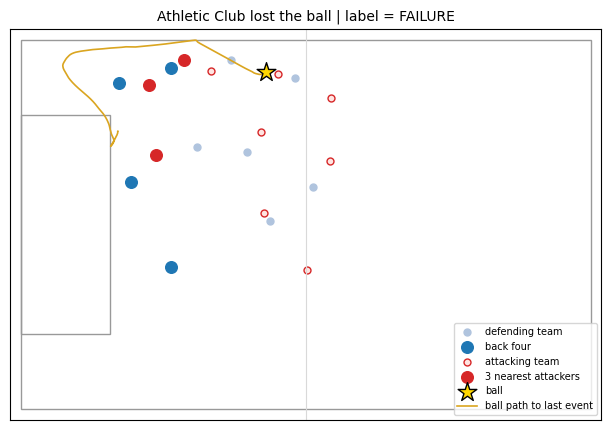

In [8]:
def next_events(ev_all, t):
    """(seq, complete, seq_all).
    Walks through ALL events after the turnover (framed or not) and counts only FRAMED ones.
    complete = True : SEQ_LEN framed events reached with no stoppage or set piece in between.
    complete = False: a stoppage or set piece came first (framed or not); seq = framed events before it
                      (None if none). Kept later only if it had already failed.
    seq     = the framed events (used for positions and windows)
    seq_all = every event up to the last one used (used to find shots, framed or not)."""
    after = ev_all[(ev_all['period'] == t['period']) & (ev_all['index'] > t['index'])].head(SEQ_LEN * 6)
    seq, seq_all = [], []
    for _, e in after.iterrows():
        if e['event_type'] in RESTART_TYPE or is_set_piece_tag(e['event_type_2']):
            return (pd.DataFrame(seq) if seq else None), False, pd.DataFrame(seq_all)
        seq_all.append(e)
        if e['has_frame']:
            seq.append(e)
            if len(seq) == SEQ_LEN:
                return pd.DataFrame(seq), True, pd.DataFrame(seq_all)
    return (pd.DataFrame(seq) if seq else None), False, pd.DataFrame(seq_all)

def label_sequence(trk, f0, f1, period, def_side, hdl, seq, gained, seq_all=None):
    """(label, box_entry, shot, eng). label 0 = failure, 1 = success."""
    m = (trk['frame'] >= f0) & (trk['frame'] <= f1) & (trk['period'] == period)
    B, F = trk['ball'][m], trk['frame'][m]
    ok = ~np.isnan(B).any(axis=1)
    B, F = B[ok], F[ok]
    box_entry = False
    eng = {'min_ball_x': np.nan, 'entered_own_half': False, 'entered_def_third': False,
           'frame_entry_def_third': np.nan, 'frame_entry_own_half': np.nan,
           'entry_event_def_third': np.nan, 'entry_event_own_half': np.nan}
    if len(B):
        B = normalize_points(B, needs_flip(def_side, period, hdl))
        box_entry = bool(((B[:, 0] <= BOX_DEPTH) & (B[:, 1] >= BOX_Y_MIN) & (B[:, 1] <= BOX_Y_MAX)).any())
        eng['min_ball_x'] = round(float(B[:, 0].min()), 2)
        ev_frames = seq['skillcorner_frame'].astype(int).to_numpy()
        for tag, thr in (('def_third', DEF_THIRD_X), ('own_half', OWN_HALF_X)):
            inside = np.flatnonzero(B[:, 0] <= thr)
            if len(inside):
                fe = int(F[inside[0]])
                after = np.flatnonzero(ev_frames >= fe)
                eng[f'entered_{tag}'] = True
                eng[f'frame_entry_{tag}'] = fe
                eng[f'entry_event_{tag}'] = int(after[0]) + 1 if len(after) else len(ev_frames)
    f_box = int(F[(B[:, 0] <= BOX_DEPTH) & (B[:, 1] >= BOX_Y_MIN) & (B[:, 1] <= BOX_Y_MAX)][0]) if box_entry else np.inf
    sa = seq if seq_all is None or len(seq_all) == 0 else seq_all      # shots: look at ALL events
    shot_mask = ((sa['event_type'].isin(['Shot', 'Penalty Won']) & (sa['team'] == gained))
                 | (sa['event_type'] == 'Own Goal Against'))
    shot = bool(shot_mask.any())
    f_shot = np.inf
    if shot:
        first = sa[shot_mask].iloc[0]
        if first['has_frame']:
            f_shot = int(first['skillcorner_frame'])
        else:   # shot without a frame: use the last framed event before it (cut features a bit early)
            prev = sa[(sa['index'] < first['index']) & sa['has_frame']]
            f_shot = int(prev['skillcorner_frame'].max()) if len(prev) else f0
    eng['frame_outcome'] = min(f_box, f_shot)          # inf for successes
    # regain: the first event where possession is back with the DEFENDING team (rare within 10 events)
    rg = sa[sa['possession_team'].notna() & (sa['possession_team'] != gained)]
    f_regain = np.inf
    if len(rg):
        e = rg.iloc[0]
        if e['has_frame']:
            f_regain = int(e['skillcorner_frame'])
        else:
            prev = sa[(sa['index'] < e['index']) & sa['has_frame']]
            f_regain = int(prev['skillcorner_frame'].max()) if len(prev) else f0
    eng['frame_regain'] = f_regain
    return (0 if (box_entry or shot) else 1), box_entry, shot, eng

import ast
ON_BALL = {'Ball Receipt*', 'Carry', 'Dribble', 'Pass', 'Shot'}

def controlled_entry(seq_all, gained):
    """Outcome definition B (SENSITIVITY ONLY): True if the team that won the ball performed an on-ball action
    (receipt, carry, dribble, pass, shot) INSIDE the box it attacks, i.e. our box. StatsBomb locations are
    oriented to the acting team (attacking towards x = 120): box = x >= 102 and 18 <= y <= 62.
    Failed receptions ('Incomplete') do not count."""
    if seq_all is None or len(seq_all) == 0:
        return False
    for _, e in seq_all.iterrows():
        if e['team'] != gained or e['event_type'] not in ON_BALL:
            continue
        if e['event_type'] == 'Ball Receipt*' and e.get('outcome') == 'Incomplete':
            continue
        loc = e.get('location')
        if isinstance(loc, str):
            loc = ast.literal_eval(loc)
        if not isinstance(loc, (list, tuple)) or len(loc) < 2:
            continue
        if loc[0] >= 102 and 18 <= loc[1] <= 62:
            return True
    return False

# ---------------- CHECK on every turnover of this match ----------------
trace = []
for _, t in turns.iterrows():
    lost, gained, per = t['prev_team'], t['possession_team'], int(t['period'])
    ds = 'h' if lost == home else 'a'
    seq, complete, seq_all = next_events(ev_all, t)
    if seq is None:
        trace.append({'lost': lost, 'status': 'stopped at once, dropped'}); continue
    f0, f1 = int(t['skillcorner_frame']), int(seq['skillcorner_frame'].max())
    label, box, shot, eng = label_sequence(trk, f0, f1, per, ds, hdl, seq, gained, seq_all)
    if not complete and label == 1:
        trace.append({'lost': lost, 'status': 'stopped early, no failure yet, dropped'}); continue
    trace.append({'lost': lost, 'status': '10 events' if complete else 'stopped early AFTER a failure, kept',
                  'label': label, 'box_entry': box, 'shot': shot,
                  'own_half': eng['entered_own_half'], 'f0': f0, 'f1': f1, 'index': t['index']})
trace = pd.DataFrame(trace)
print(trace['status'].value_counts().to_string(), "\n")
full = trace[trace['label'].notna()]          # every KEPT sequence
print(full.groupby('lost').agg(n=('label', 'size'), failures=('label', lambda x: int((x == 0).sum())),
                               reached_own_half=('own_half', 'sum')).to_string())
print("CHECK: every failure has a cause (box entry or shot):",
      'OK' if ((full['label'] == 1) | full['box_entry'] | full['shot']).all() else 'PROBLEM')

# picture: one sequence (first failure if there is one), ball path from loss to 10th event
EXAMPLE = 0
pick = full[full['label'] == 0] if (full['label'] == 0).any() else full
ex = pick.iloc[min(EXAMPLE, len(pick) - 1)]
ex_t = turns[turns['index'] == ex['index']].iloc[0]
ex_seq, _, ex_all = next_events(ev_all, ex_t)
ex_side = 'h' if ex['lost'] == home else 'a'
ex_per = int(ex_t['period'])
display(ex_all[['index', 'minute', 'second', 'team', 'event_type', 'event_type_2', 'has_frame']])
m = (trk['frame'] >= ex['f0']) & (trk['frame'] <= ex['f1']) & (trk['period'] == ex_per)
Bp = trk['ball'][m]; Bp = normalize_points(Bp[~np.isnan(Bp).any(1)], needs_flip(ex_side, ex_per, hdl))
fig, ax = plt.subplots(figsize=(7, 4.4))
s0 = frame_state(trk, ex['f0'], ex_side, ex_per, hdl)
draw_frame(ax, *s0, f"{ex['lost']} lost the ball | label = {'FAILURE' if ex['label'] == 0 else 'success'}")
ax.plot(Bp[:, 0], Bp[:, 1], color='goldenrod', lw=1.2, label='ball path to last event')
ax.legend(fontsize=7, loc='lower right'); plt.tight_layout(); plt.show()

## A8. STEP 7: features
Per frame: back four = the 4 **outfield** players of the defending team with the smallest x; 3 nearest attackers = the 3 opposing outfield players with the smallest x. Then each feature is averaged over the frames within ±30 of each of the 10 events → one row per sequence.

In [9]:
ZONES = [  # (name, weight, test(point, ball)), in PRIORITY order (Table 1, Fig. 1)
    ('central_third',  0.35, lambda p, b: p[0] <= 35.0 and 19.0 <= p[1] <= 49.0),
    ('penalty_buffer', 0.30, lambda p, b: p[0] <= BOX_DEPTH + 5 and BOX_Y_MIN - 5 <= p[1] <= BOX_Y_MAX + 5),
    ('wing_pockets',   0.20, lambda p, b: p[0] <= 25.0 and (p[1] <= 10.0 or p[1] >= FIELD_W - 10.0)),
    ('ball_radius',    0.15, lambda p, b: np.hypot(p[0] - b[0], p[1] - b[1]) <= BALL_RADIUS),
]

def space_score(Dz, Az, ball):
    """Eq. 3. Each player counts once, in its highest-priority zone."""
    cnt = {name: [0, 0] for name, _, _ in ZONES}
    for k, pts in ((0, Dz), (1, Az)):
        for p in pts:
            for name, _, test in ZONES:
                if test(p, ball):
                    cnt[name][k] += 1
                    break
    return sum(w * (cnt[n][0] - cnt[n][1]) / (cnt[n][0] + cnt[n][1] + SPACE_EPS) for n, w, _ in ZONES)

def frame_features(D, A, ball):
    if len(D) < 4 or len(A) < 3:
        return None
    B4 = D[np.argsort(D[:, 0])[:4]]
    A3 = A[np.argsort(A[:, 0])[:3]]
    try:
        hull_area = float(ConvexHull(B4).volume)          # 2-D "volume" = area
    except (QhullError, ValueError):
        hull_area = 0.0
    dmin = np.min(np.linalg.norm(A3[:, None, :] - B4[None, :, :], axis=2), axis=1)
    pda = float(dmin.mean())
    L = float(B4[:, 0].mean())
    return {'stretch_index': LAMBDA * hull_area + (1 - LAMBDA) * pda,            # Eq. 1 (manuscript)
            'hull_area': hull_area, 'pda': pda,
            'pressure_index': int((dmin < PRESS_R).sum()),                       # Eq. 2, 0-3
            'space_score': space_score(B4, A3, ball),                            # Eq. 3
            'line_height_abs': L,                                                # Eq. 4
            'line_height_rel_ball': float(ball[0] - L)}                          # Eq. 5

def feature_frames(seq, f0):
    if FEATURE_ANCHOR == "loss":
        return set(range(f0 - FEATURE_PRE_FRAMES, f0 + 1, FRAME_STEP))
    frames = set()
    for f in [int(f0)] + seq['skillcorner_frame'].astype(int).tolist():   # the loss event + the 10 events
        frames.update(range(f - FEATURE_HALF_WINDOW, f + FEATURE_HALF_WINDOW + 1, FRAME_STEP))
    return frames

def sequence_features(trk, seq, def_side, period, hdl, f0, f_end=np.inf):
    rows = []
    for f in sorted(feature_frames(seq, f0)):
        if f >= f_end:
            continue
        s = frame_state(trk, f, def_side, period, hdl)
        if s is None:
            continue
        ff = frame_features(*s)
        if ff is not None:
            rows.append(ff)
    if not rows:
        return None, 0
    return pd.DataFrame(rows).mean().add_suffix('_mean').to_dict(), len(rows)

# ---------------- CHECK on the example sequence ----------------
D, A, ball = frame_state(trk, ex['f0'], ex_side, ex_per, hdl)
ff = frame_features(D, A, ball)
i0 = trk['row_of'][int(ex['f0'])]
G = normalize_points(trk[ex_side][i0][trk['gk'][ex_side]], needs_flip(ex_side, ex_per, hdl))
G = G[~np.isnan(G).any(1)]
print("defending outfield x, sorted:", np.round(np.sort(D[:, 0]), 1))
print("own keeper x (normalized):   ", np.round(G[:, 0], 1))
print("CHECK: keeper not in the outfield list:",
      'OK' if not any(np.isclose(D, g).all(1).any() for g in G) else 'PROBLEM')
print("frame features at the loss:", {k: round(v, 2) for k, v in ff.items()})
print("CHECK: pressure 0-3, hull area >= 0, line height inside the pitch:",
      'OK' if 0 <= ff['pressure_index'] <= 3 and ff['hull_area'] >= 0 and 0 <= ff['line_height_abs'] <= FIELD_L
      else 'PROBLEM')
feats, n_fr = sequence_features(trk, ex_seq, ex_side, ex_per, hdl, int(ex['f0']))
print(f"\nsequence: {n_fr} frames in the window (before cutting at the end of the defending phase)")
print({k: round(v, 3) for k, v in feats.items()})

defending outfield x, sorted: [18.2 20.4 27.6 27.6 32.4 38.8 41.7 46.  50.5 53.8]
own keeper x (normalized):    [4.3]
CHECK: keeper not in the outfield list: OK
frame features at the loss: {'stretch_index': 113.41, 'hull_area': 221.97, 'pda': 4.86, 'pressure_index': 1, 'space_score': 0.09, 'line_height_abs': 23.46, 'line_height_rel_ball': 21.8}
CHECK: pressure 0-3, hull area >= 0, line height inside the pitch: OK

sequence: 121 frames in the window (before cutting at the end of the defending phase)
{'stretch_index_mean': 39.689, 'hull_area_mean': 75.195, 'pda_mean': 4.183, 'pressure_index_mean': 1.14, 'space_score_mean': 0.074, 'line_height_abs_mean': 18.168, 'line_height_rel_ball_mean': 6.975}


## A9. One match through `process_match`
Same steps as A3-A8 in one function. The counts must add up.

In [10]:
def process_match(match_dir):
    log = {'match': match_dir, 'turnovers': 0, 'setpiece_restart': 0, 'unknown_team': 0, 'no_frame': 0,
           'few_players': 0, 'short_sequence': 0, 'loss_in_box': 0, 'no_features': 0, 'kept': 0,
           'glued_setpiece_tags': 0, 'kept_failed_before_stoppage': 0, 'events_without_frame': 0}
    loaded = load_match(match_dir)
    if loaded is None:
        log['status'] = 'missing files'
        return [], log
    events, tracking, match = loaded
    home, away = TEAM_NAMES[match['home_team']['name']], TEAM_NAMES[match['away_team']['name']]
    trk = build_tracking(tracking, match)
    hdl = home_defends_left(trk)
    ev = sync_events(events, trk)
    ev_all = order_all_events(events, ev)
    log['events_without_frame'] = int((~ev_all['has_frame']).sum())
    tags = ev['event_type_2'].dropna().astype(str)
    log['glued_setpiece_tags'] = int((tags.map(is_set_piece_tag) & ~tags.isin(RESTART_TYPE2)).sum())
    turns, n_restart = find_turnovers(ev, ev_all)
    log['turnovers'], log['setpiece_restart'] = len(turns) + n_restart, n_restart

    rows = []
    for _, t in turns.iterrows():
        lost, gained, period = t['prev_team'], t['possession_team'], int(t['period'])
        if lost not in (home, away):
            log['unknown_team'] += 1; continue
        def_side = 'h' if lost == home else 'a'
        f0 = int(t['skillcorner_frame'])
        st = frame_state(trk, f0, def_side, period, hdl)
        if st is None:
            log['no_frame'] += 1; continue
        D0, _, ball0 = st
        if len(D0) < 4:                                   # Methods criterion (2)
            log['few_players'] += 1; continue
        seq, complete, seq_all = next_events(ev_all, t)
        if seq is None:
            log['short_sequence'] += 1; continue
        f1 = int(seq['skillcorner_frame'].max())
        label, box_entry, shot, eng = label_sequence(trk, f0, f1, period, def_side, hdl, seq, gained, seq_all)
        if not complete and label == 1:                   # stopped early, outcome unknown: drop
            log['short_sequence'] += 1; continue
        loss_in_box = bool(ball0[0] <= BOX_DEPTH and BOX_Y_MIN <= ball0[1] <= BOX_Y_MAX)
        if EXCLUDE_LOSS_IN_BOX and loss_in_box:
            log['loss_in_box'] += 1; continue
        # features cover the DEFENDING PHASE only: up to the outcome (failure), or the 10th event / an
        # earlier regain (success). No frames after the 10th event are used.
        f_end = min(eng['frame_outcome'], eng['frame_regain'], f1 + 1)
        feats, n_frames = sequence_features(trk, seq, def_side, period, hdl, f0, f_end=f_end)
        if feats is None:
            log['no_features'] += 1; continue
        if not complete:
            log['kept_failed_before_stoppage'] += 1
        # outcome definition B (sensitivity): controlled entry or shot / own goal. Not used by the main analysis.
        ctrl = controlled_entry(seq_all, gained)
        label_B = 0 if (ctrl or shot) else 1
        valid_B = bool(complete or label_B == 0)          # same stoppage rule as A, applied to B
        rows.append({'match_id': match_dir, 'transition_idx': t['index'], 'label': label,
                     'home_team': home, 'away_team': away,
                     'team_lost_possession': lost, 'team_gained_possession': gained, 'period': period,
                     'player_lost_possession': t['prev_player'],
                     'loss_event_type': t['prev_type'], 'turnover_event_type': t['event_type'],
                     'frame_loss': f0, 'frame_last_event': f1,
                     'n_events': len(seq), 'n_events_incl_unframed': len(seq_all), 'complete_10_events': complete,
                     'ball_x_at_loss': round(float(ball0[0]), 2), 'ball_y_at_loss': round(float(ball0[1]), 2),
                     'box_entry': box_entry, 'shot_against': shot, 'loss_in_box': loss_in_box,
                     'controlled_entry': ctrl, 'label_B': label_B, 'valid_B': valid_B, **eng,
                     'frame_feature_end': f_end, 'n_feature_frames': n_frames, **feats})
        log['kept'] += 1
    return rows, log

# ---------------- CHECK ----------------
rows, log = process_match(DEBUG_MATCH)
print(log)
dropped = sum(log[k] for k in ('setpiece_restart', 'unknown_team', 'no_frame', 'few_players',
                               'short_sequence', 'loss_in_box', 'no_features'))
print("CHECK: turnovers = dropped + kept:", 'OK' if log['turnovers'] == dropped + log['kept'] else 'PROBLEM')
match_df = pd.DataFrame(rows)
if log['few_players'] or log['no_frame'] or log['no_features']:
    print("CHECK: some turnovers had a missing frame or < 4 outfield players; compare A7 and A9 counts by hand")
else:
    print("CHECK: same number of full sequences as A7 (minus losses in the box):",
          'OK' if log['kept'] == len(full) - log['loss_in_box'] else 'PROBLEM')
display(match_df[['team_lost_possession', 'label', 'ball_x_at_loss', 'entered_own_half', 'n_feature_frames'] + FEATURES].head(8))

{'match': '1021404', 'turnovers': 129, 'setpiece_restart': 37, 'unknown_team': 0, 'no_frame': 0, 'few_players': 0, 'short_sequence': 22, 'loss_in_box': 0, 'no_features': 0, 'kept': 70, 'glued_setpiece_tags': 2, 'kept_failed_before_stoppage': 1, 'events_without_frame': 318}
CHECK: turnovers = dropped + kept: OK
CHECK: same number of full sequences as A7 (minus losses in the box): OK


,team_lost_possession,label,ball_x_at_loss,entered_own_half,n_feature_frames,line_height_rel_ball_mean,line_height_abs_mean,stretch_index_mean,pressure_index_mean,space_score_mean
0,Real Madrid,1,57.64,False,111,35.291689,39.102905,13.936755,0.234234,0.000563
1,Athletic Club,1,66.39,False,138,26.546993,40.327065,43.179862,0.166667,-0.011413
2,Real Madrid,1,97.97,False,146,28.796284,54.261592,70.600630,0.280822,0.000000
3,Real Madrid,1,87.03,True,106,25.607123,55.017028,96.843958,0.754717,-0.012736
4,Athletic Club,1,62.52,True,89,22.558090,33.814831,75.187216,0.674157,0.011798
5,Real Madrid,1,76.15,True,94,17.943830,43.539468,82.777686,0.063830,0.034574
6,Real Madrid,1,66.10,True,105,18.433810,39.136857,62.201755,0.533333,0.064127
7,Athletic Club,1,90.69,True,104,14.793245,52.920409,79.402641,0.451923,-0.020913


## A10. Full run, all matches (about 10 minutes)
Set `RUN_FULL = False` to reload the CSV saved by the last full run instead.

In [11]:
def main(out_csv=OUT_CSV):
    rows_all, logs = [], []
    for d in tqdm(list_matches()):
        rows, log = process_match(d)
        rows_all += rows
        logs.append(log)
    out = pd.DataFrame(rows_all)
    os.makedirs(os.path.dirname(out_csv), exist_ok=True)
    out.to_csv(out_csv, index=False)
    return out, pd.DataFrame(logs)

RUN_FULL = True
if RUN_FULL:
    features_corrected, pipeline_log = main()
    print(pipeline_log.sum(numeric_only=True).to_string())
    print("skipped folders:", pipeline_log.loc[pipeline_log.get('status').notna(), 'match'].tolist()
          if 'status' in pipeline_log else 'none')
else:
    features_corrected = pd.read_csv(OUT_CSV)

print(f"\nrows: {len(features_corrected):,}")
print("""last run (before the glued-tag fix): turnovers 7,287 | setpiece_restart 1,321 | short_sequence 1,213
                                      loss_in_box 13 | kept 4,740 | skipped: ['sorry']
Expected now: MORE failures than before ('kept_failed_before_stoppage' > 0), fewer short_sequence.""")
print("CHECK: matches per team:",
      features_corrected.groupby('team_lost_possession')['match_id'].nunique().reindex(TEAMS).to_dict(),
      "(expected Barcelona 38, Real Madrid 37)")

100%|██████████| 74/74 [07:27<00:00,  6.05s/it]

turnovers                       7287
setpiece_restart                2514
unknown_team                       0
no_frame                           0
few_players                        0
short_sequence                  1031
loss_in_box                        7
no_features                        0
kept                            3735
glued_setpiece_tags              103
kept_failed_before_stoppage      120
events_without_frame           24272
skipped folders: ['sorry']

rows: 3,735
last run (before the glued-tag fix): turnovers 7,287 | setpiece_restart 1,321 | short_sequence 1,213
                                      loss_in_box 13 | kept 4,740 | skipped: ['sorry']
Expected now: MORE failures than before ('kept_failed_before_stoppage' > 0), fewer short_sequence.
CHECK: matches per team: {'Barcelona': 38, 'Real Madrid': 37} (expected Barcelona 38, Real Madrid 37)


## A11. The analysis sample
Barcelona or Real Madrid lost the ball (anywhere), and the ball then reached their own half (x ≤ 52.5) at some point within the 10 events.

In [12]:
two = features_corrected[features_corrected['team_lost_possession'].isin(TEAMS)]
main_sample = two[two['entered_own_half']].copy()
main_sample['outcome'] = main_sample['label'].map({0: 'Failure', 1: 'Success'})

print(f"all sequences, all teams      : {len(features_corrected):,}   (last run 4,740)")
print(f"Barcelona / Real Madrid lost  : {len(two):,}   (last run 2,378)")
print(f"... and ball reached own half : {len(main_sample):,}   (last run 1,365)")
tab = pd.crosstab(main_sample['team_lost_possession'], main_sample['outcome'], margins=True)
tab['failure %'] = (100 * tab['Failure'] / tab['All']).round(1)
display(tab)
print("last run: Barcelona 134 / 554 (688), Real Madrid 114 / 563 (677), failure 18.2%")
print("CHECK: no loss inside own box:", 'OK' if not main_sample['loss_in_box'].any() else 'PROBLEM')
print("CHECK: no missing feature values:", 'OK' if main_sample[FEATURES].notna().all().all() else 'PROBLEM')
display(main_sample[FEATURES].describe().round(3))

all sequences, all teams      : 3,735   (last run 4,740)
Barcelona / Real Madrid lost  : 1,853   (last run 2,378)
... and ball reached own half : 1,001   (last run 1,365)


outcome,Failure,Success,All,failure %
team_lost_possession,,,,
Barcelona,111,404,515,21.6
Real Madrid,91,395,486,18.7
All,202,799,1001,20.2


last run: Barcelona 134 / 554 (688), Real Madrid 114 / 563 (677), failure 18.2%
CHECK: no loss inside own box: OK
CHECK: no missing feature values: OK


,line_height_rel_ball_mean,line_height_abs_mean,stretch_index_mean,pressure_index_mean,space_score_mean
count,1001.000,1001.000,1001.000,1001.000,1001.000
mean,13.811,38.940,62.041,0.679,0.042
std,8.089,12.657,29.965,0.409,0.056
min,-12.851,7.896,6.863,0.000,-0.060
25%,7.819,29.293,40.742,0.375,0.000
50%,13.122,39.317,57.456,0.638,0.027
75%,19.028,48.378,78.710,0.956,0.075
max,42.465,76.100,205.598,2.356,0.283


## B1. Table 2: two-way ANOVA (Team × Outcome) and Fig. 3
Every effect with its df, including non-significant ones. Significance shown at .05 and at the Bonferroni level .01 (5 features). No class balancing.

=== Mean, SD, n per Team x Outcome cell (raw units) ===


team_lost_possession         Barcelona          Real Madrid         
outcome                        Failure  Success     Failure  Success
Line height (relative) mean      8.116   14.382       9.647   15.786
Line height (relative) std       8.518    7.660       7.183    7.523
Line height (relative) count   111.000  404.000      91.000  395.000
Line height (absolute) mean     37.104   40.194      33.241   39.487
Line height (absolute) std      13.249   12.209      13.726   12.318
Line height (absolute) count   111.000  404.000      91.000  395.000
Stretch index mean              63.538   60.080      64.994   62.947
Stretch index std               34.148   28.671      33.156   29.225
Stretch index count            111.000  404.000      91.000  395.000
Pressure index mean              0.748    0.748       0.615    0.603
Pressure index std               0.444    0.400       0.367    0.402
Pressure index count           111.000  404.000      91.000  395.000
Space score mean                 0.042    0.035       0.049    0.047
Space score std                  0.048    0.052       0.054    0.062
Space score count              111.000  404.000      91.000  395.000

=== Table 2 ===


,feature,effect,df,df_error,F,p,eta2_p,sig .05,sig .01 (Bonf.)
0,Line height (relative),Team,1,997,8.6905,0.0033,0.0086,yes,yes
1,Line height (relative),Outcome,1,997,105.6292,0.0000,0.0958,yes,yes
2,Line height (relative),Team * Outcome,1,997,0.0108,0.9172,0.0000,no,no
3,Line height (absolute),Team,1,997,2.8606,0.0911,0.0029,no,no
4,Line height (absolute),Outcome,1,997,21.1939,0.0000,0.0208,yes,yes
5,Line height (absolute),Team * Outcome,1,997,2.5425,0.1111,0.0025,no,no
6,Stretch index,Team,1,997,1.8590,0.1730,0.0019,no,no
7,Stretch index,Outcome,1,997,1.4164,0.2343,0.0014,no,no
8,Stretch index,Team * Outcome,1,997,0.0889,0.7657,0.0001,no,no
9,Pressure index,Team,1,997,31.2767,0.0000,0.0304,yes,yes


last run: Rel. LH Outcome F = 258.68, eta2_p = .160; no interaction p < .05


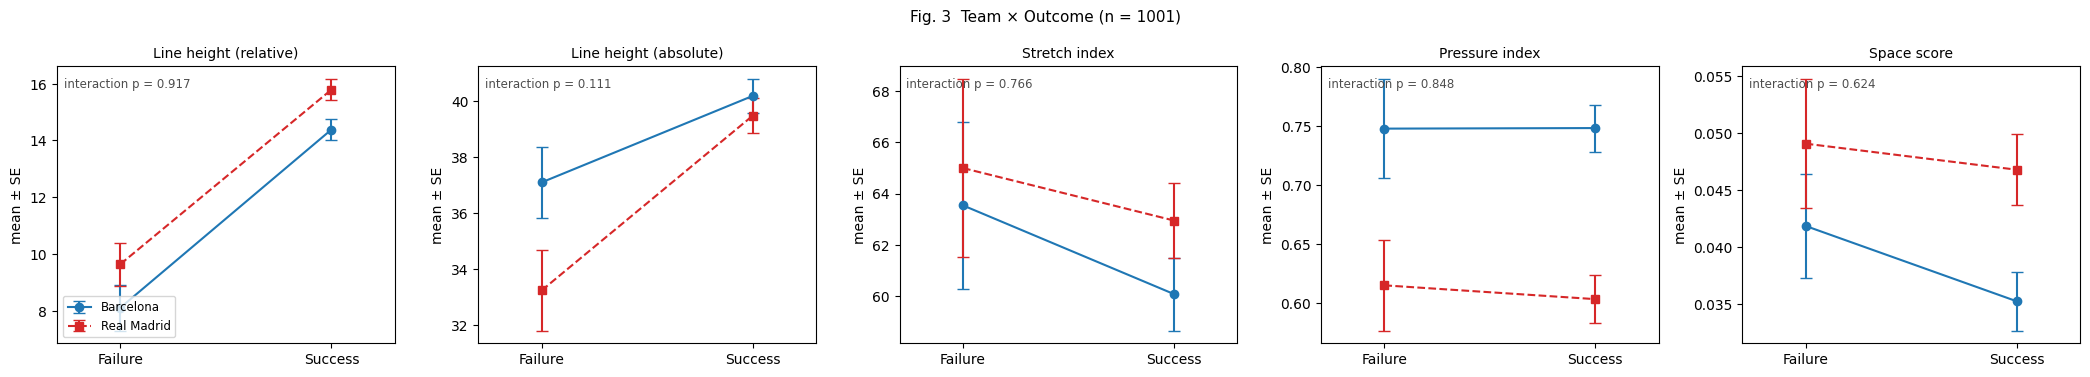

In [13]:
import pingouin as pg

ALPHA_BONF = 0.05 / len(FEATURES)

def two_way_anova(df):
    rows = []
    for f in FEATURES:
        d = df[['team_lost_possession', 'label', f]].dropna()
        a = pg.anova(dv=f, between=['team_lost_possession', 'label'], data=d, detailed=True)
        pcol = 'p-unc' if 'p-unc' in a.columns else 'p_unc'
        df_err = int(a.loc[a['Source'] == 'Residual', 'DF'].iloc[0])
        for _, x in a[a['Source'] != 'Residual'].iterrows():
            rows.append({'feature': NICE[f],
                         'effect': x['Source'].replace('team_lost_possession', 'Team').replace('label', 'Outcome'),
                         'df': int(x['DF']), 'df_error': df_err, 'F': float(x['F']),
                         'p': float(x[pcol]), 'eta2_p': float(x['np2'])})
    out = pd.DataFrame(rows)
    out['sig .05'] = np.where(out['p'] < 0.05, 'yes', 'no')
    out['sig .01 (Bonf.)'] = np.where(out['p'] < ALPHA_BONF, 'yes', 'no')
    return out

desc = main_sample.groupby(['team_lost_possession', 'outcome'])[FEATURES].agg(['mean', 'std', 'count']).round(3)
desc.columns = [f"{NICE[f]} {s}" for f, s in desc.columns]
print("=== Mean, SD, n per Team x Outcome cell (raw units) ===")
display(desc.T)

table2 = two_way_anova(main_sample)
print("=== Table 2 ===")
display(table2.round(4))
table2.to_csv(os.path.join(OUT_DIR, 'table2_anova.csv'), index=False)
print("last run: Rel. LH Outcome F = 258.68, eta2_p = .160; no interaction p < .05")

fig, axs = plt.subplots(1, 5, figsize=(21, 3.8))
for ax, f in zip(axs, FEATURES):
    for team, col, ls, mk in (('Barcelona', 'tab:blue', '-', 'o'), ('Real Madrid', 'tab:red', '--', 's')):
        g = main_sample[main_sample['team_lost_possession'] == team].groupby('label')[f].agg(['mean', 'sem']).reindex([0, 1])
        ax.errorbar([0, 1], g['mean'], yerr=g['sem'], color=col, ls=ls, marker=mk, capsize=4, label=team)
    p_int = table2.loc[(table2['feature'] == NICE[f]) & (table2['effect'] == 'Team * Outcome'), 'p'].iloc[0]
    ax.text(0.02, 0.96, f"interaction p = {p_int:.3f}", transform=ax.transAxes, fontsize=8.5, va='top', color='0.3')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Failure', 'Success']); ax.set_xlim(-0.3, 1.3)
    ax.set_title(NICE[f], fontsize=10); ax.set_ylabel('mean ± SE')
axs[0].legend(fontsize=8.5, loc='lower left')
plt.suptitle(f'Fig. 3  Team × Outcome (n = {len(main_sample)})', fontsize=11)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'fig3_interaction.png'), dpi=300); plt.show()

## B2. Table 3: success vs failure within each team (95% CI), and conditional post-hoc tests
**Table 3** reports, for each team and feature, the success - failure mean difference with its 95% CI (Welch) and Hedges' g. It is descriptive, with no p-values.

**Post-hoc tests** follow the manuscript's rule: they run only for features with a significant Team × Outcome interaction (α = .01). If there are none, nothing is tested. If there are, Welch t-tests are run within each team with Bonferroni correction over the number of tests run.

In [14]:
from scipy import stats

def welch(a, b):
    """success (a) minus failure (b): difference, 95% CI, t, Welch df, two-sided p."""
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    diff, se = a.mean() - b.mean(), np.sqrt(va + vb)
    dof = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
    q, t = stats.t.ppf(0.975, dof), diff / se
    return diff, diff - q * se, diff + q * se, t, dof, 2 * stats.t.sf(abs(t), dof)

def hedges_g(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (1 - 3 / (4 * (na + nb) - 9)) * (a.mean() - b.mean()) / sp

def split(team, f):
    d = main_sample[main_sample['team_lost_possession'] == team]
    return d.loc[d['label'] == 1, f].to_numpy(float), d.loc[d['label'] == 0, f].to_numpy(float)

# ---------------- Table 3: success - failure mean difference with 95% CI (descriptive, no p-values) ----------------
rows = []
for team in TEAMS:
    for f in FEATURES:
        a, b = split(team, f)
        diff, lo, hi, *_ = welch(a, b)
        rows.append({'team': team, 'feature': NICE[f], 'n S': len(a), 'n F': len(b),
                     'mean S': a.mean(), 'mean F': b.mean(), 'diff (S - F)': diff,
                     '95% CI low': lo, '95% CI high': hi, 'Hedges g': hedges_g(a, b)})
table3 = pd.DataFrame(rows)
print("=== Table 3: success - failure, mean difference with 95% CI (raw units) ===")
display(table3.round(3))
table3.to_csv(os.path.join(OUT_DIR, 'table3_mean_differences.csv'), index=False)

# ---------------- Post-hoc tests: ONLY if a Team x Outcome interaction is significant (manuscript rule) ----------------
inter = table2.loc[(table2['effect'] == 'Team * Outcome') & (table2['p'] < ALPHA_BONF), 'feature'].tolist()
if not inter:
    print(f"\nPost-hoc: no significant Team x Outcome interaction (alpha = {ALPHA_BONF:.2f}), so no post-hoc tests "
          "are run (manuscript rule).")
    posthoc = pd.DataFrame()
else:
    rows = []
    for f in [c for c in FEATURES if NICE[c] in inter]:
        for team in TEAMS:
            a, b = split(team, f)
            diff, lo, hi, t, dof, p = welch(a, b)
            rows.append({'feature': NICE[f], 'team': team, 'diff (S - F)': diff, '95% CI low': lo, '95% CI high': hi,
                         't': t, 'df': dof, 'p': p, 'Hedges g': hedges_g(a, b)})
    posthoc = pd.DataFrame(rows)
    m = len(posthoc)
    posthoc['p Bonferroni'] = np.minimum(posthoc['p'] * m, 1.0)
    posthoc['sig'] = np.where(posthoc['p Bonferroni'] < 0.05, 'yes', 'no')
    print(f"\n=== Post-hoc: Welch t-tests within each team, for features with a significant interaction ===")
    print(f"Bonferroni over the {m} tests run (alpha = .05/{m} = {0.05 / m:.4f})")
    display(posthoc.round(4))
    posthoc.to_csv(os.path.join(OUT_DIR, 'posthoc_within_team.csv'), index=False)

# ---------------- CHECK ----------------
a, b = split(TEAMS[0], FEATURES[0])
ref = pg.ttest(a, b, correction=True)                      # pingouin's Welch test on the same data
pcol = [c for c in ref.columns if c.lower().replace('-', '_') == 'p_val'][0]
p_ours = welch(a, b)[5]
print("\nCHECK: our Welch test matches pingouin:",
      'OK' if np.isclose(p_ours, float(ref[pcol].iloc[0]), rtol=1e-6, atol=1e-300) else 'PROBLEM')


=== Table 3: success - failure, mean difference with 95% CI (raw units) ===


,team,feature,n S,n F,mean S,mean F,diff (S - F),95% CI low,95% CI high,Hedges g
0,Barcelona,Line height (relative),404,111,14.382,8.116,6.266,4.501,8.031,0.797
1,Barcelona,Line height (absolute),404,111,40.194,37.104,3.091,0.333,5.848,0.248
2,Barcelona,Stretch index,404,111,60.080,63.538,-3.459,-10.454,3.537,-0.115
3,Barcelona,Pressure index,404,111,0.748,0.748,0.000,-0.092,0.093,0.001
4,Barcelona,Space score,404,111,0.035,0.042,-0.007,-0.017,0.004,-0.129
5,Real Madrid,Line height (relative),395,91,15.786,9.647,6.140,4.473,7.806,0.822
6,Real Madrid,Line height (absolute),395,91,39.487,33.241,6.246,3.145,9.346,0.495
7,Real Madrid,Stretch index,395,91,62.947,64.994,-2.046,-9.516,5.423,-0.068
8,Real Madrid,Pressure index,395,91,0.603,0.615,-0.012,-0.098,0.074,-0.030
9,Real Madrid,Space score,395,91,0.047,0.049,-0.002,-0.015,0.011,-0.038



Post-hoc: no significant Team x Outcome interaction (alpha = 0.01), so no post-hoc tests are run (manuscript rule).

CHECK: our Welch test matches pingouin: OK


## B3. Table 4 and Table 5: class-weighted models on ALL sequences, and SHAP
Main analysis. Every sequence is used. The 18% failure class is up-weighted in training (class weights; XGBoost `scale_pos_weight` = failures / successes), as in the manuscript. Separate models per team, stratified 80/20 split (seed 42), 5-fold CV on the training set, scaling fitted on training data only. The test set keeps the real failure rate, so imbalance-robust metrics are reported next to ROC AUC (which does not depend on the class balance).

=== Table 4: class-weighted models, all sequences ===
chance levels: ROC AUC 0.5 | balanced accuracy 0.5 | PR-AUC failure = test failure rate


,team,algorithm,n train,n test,test failure rate,test AUC,AUC CI low,AUC CI high,CV AUC,CV AUC SD,balanced accuracy,failure recall,failure precision,PR-AUC failure,accuracy,precision,recall,F1
0,Barcelona,XGBoost,412,103,0.214,0.808,0.680,0.919,0.649,0.110,0.759,0.727,0.485,0.633,0.777,0.914,0.790,0.848
1,Barcelona,Random Forest,412,103,0.214,0.813,0.700,0.914,0.689,0.100,0.657,0.364,0.667,0.634,0.825,0.846,0.951,0.895
2,Barcelona,SVM (RBF),412,103,0.214,0.830,0.739,0.914,0.707,0.090,0.769,0.773,0.472,0.533,0.767,0.925,0.765,0.838
3,Real Madrid,XGBoost,388,98,0.184,0.768,0.602,0.910,0.678,0.078,0.770,0.778,0.424,0.527,0.765,0.938,0.762,0.841
4,Real Madrid,Random Forest,388,98,0.184,0.724,0.568,0.866,0.725,0.057,0.601,0.278,0.455,0.450,0.806,0.851,0.925,0.886
5,Real Madrid,SVM (RBF),388,98,0.184,0.773,0.637,0.895,0.721,0.085,0.715,0.667,0.387,0.533,0.745,0.910,0.762,0.830


last run (class-weighted, old pipeline): test AUC .57-.73


SHAP rank                                 mean |SHAP|                              
team                       Barcelona           Real Madrid             Barcelona           Real Madrid        
model                  Random Forest XGBoost Random Forest XGBoost Random Forest XGBoost Random Forest XGBoost
feature                                                                                                       
Line height (absolute)           4.0     4.0           2.0     2.0         0.043   0.235         0.098   0.649
Line height (relative)           1.0     1.0           1.0     1.0         0.171   1.005         0.139   0.933
Pressure index                   5.0     3.0           5.0     4.0         0.040   0.288         0.043   0.363
Space score                      2.0     2.0           3.0     3.0         0.074   0.593         0.059   0.407
Stretch index                    3.0     5.0           4.0     5.0         0.048   0.226         0.045   0.341

last run: XGBoost top 2 = the two line heights, for both teams
CHECK: Barcelona and Real Madrid models are different objects: OK


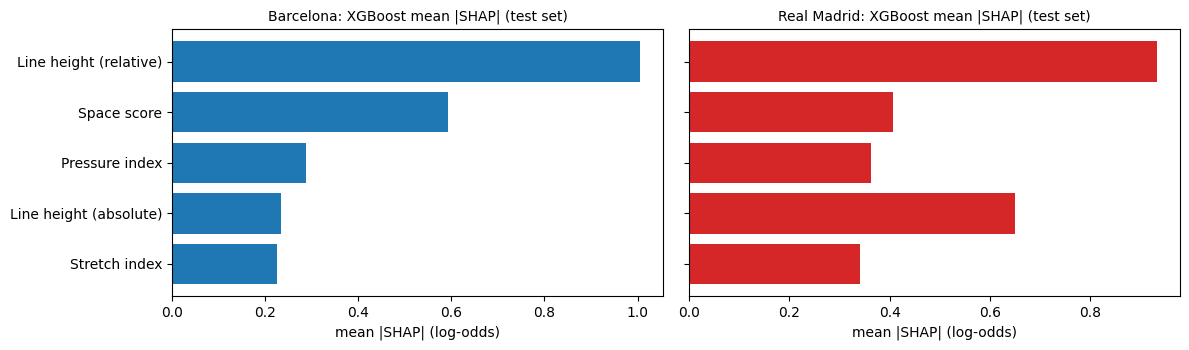

In [15]:
import shap
import xgboost as xgb
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, balanced_accuracy_score)
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

N_DRAWS = 20

def balance_50_50(df, seed):
    parts = []
    for team in TEAMS:
        t = df[df['team_lost_possession'] == team]
        fail, succ = t[t['label'] == 0], t[t['label'] == 1]
        k = min(len(fail), len(succ))
        parts += [fail.sample(k, random_state=seed), succ.sample(k, random_state=seed)]
    return pd.concat(parts).reset_index(drop=True)

def make_models(y_train=None, weighted=False):
    if weighted:     # used in B4 only
        spw = float((y_train == 0).sum()) / float((y_train == 1).sum())
        return {'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, scale_pos_weight=spw,
                                         random_state=SEED, eval_metric='logloss', verbosity=0),
                'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_split=5,
                                                        class_weight='balanced', random_state=SEED),
                'SVM (RBF)': SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=SEED)}
    return {'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3,
                                     random_state=SEED, eval_metric='logloss', verbosity=0),
            'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_split=5, random_state=SEED),
            'SVM (RBF)': SVC(kernel='rbf', probability=True, random_state=SEED)}

def bootstrap_auc(y, p, n_boot=2000):
    r = np.random.default_rng(SEED); y, p = np.asarray(y), np.asarray(p); a = []
    for _ in range(n_boot):
        i = r.integers(0, len(y), len(y))
        if len(np.unique(y[i])) == 2:
            a.append(roc_auc_score(y[i], p[i]))
    return np.percentile(a, 2.5), np.percentile(a, 97.5)

def fit_team(df, team, seed=SEED, weighted=False, only=None):
    """Fits every model for one team. Returns (rows, fitted pipelines, X_test, split table)."""
    d = df[df['team_lost_possession'] == team].reset_index(drop=True)
    X, y = d[FEATURES], d['label'].astype(int)
    itr, ite = train_test_split(np.arange(len(d)), test_size=0.2, stratify=y, random_state=seed)
    Xtr, Xte, ytr, yte = X.iloc[itr], X.iloc[ite], y.iloc[itr], y.iloc[ite]
    rows, fitted = [], {}
    for name, model in make_models(ytr, weighted).items():
        if only and name != only:
            continue
        pipe = make_pipeline(StandardScaler(), clone(model)).fit(Xtr, ytr)
        fitted[name] = pipe
        p_tr, p_te, pred = pipe.predict_proba(Xtr)[:, 1], pipe.predict_proba(Xte)[:, 1], pipe.predict(Xte)
        cv = cross_val_score(make_pipeline(StandardScaler(), clone(model)), Xtr, ytr,
                             cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring='roc_auc')
        row = {'team': team, 'algorithm': name, 'n train': len(ytr), 'n test': len(yte),
               'train AUC': roc_auc_score(ytr, p_tr), 'test AUC': roc_auc_score(yte, p_te),
               'CV AUC': cv.mean(), 'CV AUC SD': cv.std(ddof=1)}
        if not only:
            lo, hi = bootstrap_auc(yte, p_te)
            row.update({'AUC CI low': lo, 'AUC CI high': hi,
                        'accuracy': accuracy_score(yte, pred), 'precision': precision_score(yte, pred, zero_division=0),
                        'recall': recall_score(yte, pred, zero_division=0), 'F1': f1_score(yte, pred, zero_division=0),
                        'test failure rate': float((yte == 0).mean()),
                        'PR-AUC failure': average_precision_score(1 - yte, 1 - p_te),
                        'failure recall': recall_score(yte, pred, pos_label=0, zero_division=0),
                        'failure precision': precision_score(yte, pred, pos_label=0, zero_division=0),
                        'balanced accuracy': balanced_accuracy_score(yte, pred)})
        rows.append(row)
    split = pd.DataFrame({'team': team, 'match_id': d['match_id'], 'transition_idx': d['transition_idx'],
                          'set': np.where(np.isin(np.arange(len(d)), itr), 'train', 'test')})
    return rows, fitted, Xte, split

# ---- Table 4 (MAIN): class-weighted models on ALL sequences ----
rows, fitted, Xtest, splits = [], {}, {}, []
for team in TEAMS:
    r, f, xte, sp = fit_team(main_sample, team, weighted=True)
    rows += r; fitted[team] = f; Xtest[team] = xte; splits.append(sp)
table4 = pd.DataFrame(rows)
cols4 = ['team', 'algorithm', 'n train', 'n test', 'test failure rate', 'test AUC', 'AUC CI low', 'AUC CI high',
         'CV AUC', 'CV AUC SD', 'balanced accuracy', 'failure recall', 'failure precision', 'PR-AUC failure',
         'accuracy', 'precision', 'recall', 'F1']
print("=== Table 4: class-weighted models, all sequences ===")
print("chance levels: ROC AUC 0.5 | balanced accuracy 0.5 | PR-AUC failure = test failure rate")
display(table4[cols4].round(3))
table4.to_csv(os.path.join(OUT_DIR, 'table4_class_weighted.csv'), index=False)
pd.concat(splits).to_csv(os.path.join(OUT_DIR, 'table4_split_indices.csv'), index=False)
print("last run (class-weighted, old pipeline): test AUC .57-.73")

# ---- Table 5: importance + mean |SHAP| per team, test set ----
def mean_abs_shap(pipe, Xte):
    est, Xs = pipe[-1], pipe[:-1].transform(Xte)
    if isinstance(est, XGBClassifier):       # XGBoost's own exact TreeSHAP
        contrib = est.get_booster().predict(xgb.DMatrix(Xs), pred_contribs=True)
        return np.abs(contrib[:, :-1]).mean(axis=0)
    sv = shap.TreeExplainer(est).shap_values(Xs)
    sv = np.asarray(sv[1] if isinstance(sv, list) else sv)
    if sv.ndim == 3:
        sv = sv[:, :, 1]
    return np.abs(sv).mean(axis=0)

rows = []
for team in TEAMS:
    for name in ('XGBoost', 'Random Forest'):
        pipe = fitted[team][name]
        for f, imp, sh in zip(FEATURES, pipe[-1].feature_importances_, mean_abs_shap(pipe, Xtest[team])):
            rows.append({'team': team, 'model': name, 'feature': NICE[f], 'importance': imp, 'mean |SHAP|': sh})
table5 = pd.DataFrame(rows)
table5['SHAP rank'] = table5.groupby(['team', 'model'])['mean |SHAP|'].rank(ascending=False).astype(int)
display(table5.pivot_table(index='feature', columns=['team', 'model'], values=['SHAP rank', 'mean |SHAP|']).round(3))
table5.to_csv(os.path.join(OUT_DIR, 'table5_shap.csv'), index=False)
print("last run: XGBoost top 2 = the two line heights, for both teams")
print("CHECK: Barcelona and Real Madrid models are different objects:",
      'OK' if not np.allclose(fitted['Barcelona']['XGBoost'][-1].feature_importances_,
                              fitted['Real Madrid']['XGBoost'][-1].feature_importances_) else 'PROBLEM')

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, team in zip(axs, TEAMS):
    t = table5[(table5['team'] == team) & (table5['model'] == 'XGBoost')].sort_values('mean |SHAP|')
    ax.barh(t['feature'], t['mean |SHAP|'], color='tab:blue' if team == 'Barcelona' else 'tab:red')
    ax.set_title(f'{team}: XGBoost mean |SHAP| (test set)', fontsize=10); ax.set_xlabel('mean |SHAP| (log-odds)')
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'fig_shap.png'), dpi=300); plt.show()

## B4. Supplementary: balanced 50/50 (undersampling), stability over 20 draws, and the overfitting check
Sensitivity analysis. Within each team, successes are randomly undersampled to the number of failures (exact 50/50). Repeated with 20 random draws to show how much the result depends on which successes are kept. The overfitting check compares training AUC with test and CV AUC for both settings.

In [16]:
# ---- balanced 50/50 (seed 42) ----
bal = balance_50_50(main_sample, SEED)
display(pd.crosstab(bal['team_lost_possession'], bal['outcome'], margins=True))
rows = []
for team in TEAMS:
    r, *_ = fit_team(bal, team)
    rows += r
tableS4 = pd.DataFrame(rows)
print("=== Supplementary Table: balanced 50/50 (chance = 0.5 for every metric) ===")
display(tableS4[['team', 'algorithm', 'n train', 'n test', 'test AUC', 'AUC CI low', 'AUC CI high', 'CV AUC',
                 'accuracy', 'precision', 'recall', 'F1']].round(3))
tableS4.to_csv(os.path.join(OUT_DIR, 'tableS4_balanced.csv'), index=False)

# ---- stability over 20 balanced draws (XGBoost) ----
stab = []
for s in range(N_DRAWS):
    b = balance_50_50(main_sample, 1000 + s)
    for team in TEAMS:
        r, *_ = fit_team(b, team, seed=1000 + s, only='XGBoost')
        stab.append({'team': team, 'draw': s, 'test AUC': r[0]['test AUC'], 'CV AUC': r[0]['CV AUC']})
stab = pd.DataFrame(stab)
print(f"=== XGBoost over {N_DRAWS} balanced draws (each with its own split) ===")
display(stab.groupby('team')[['CV AUC', 'test AUC']].describe(percentiles=[.025, .975])
            .loc[:, (slice(None), ['mean', '2.5%', '97.5%'])].round(3))
stab.to_csv(os.path.join(OUT_DIR, 'tableS4_stability.csv'), index=False)

# ---- overfitting check: train vs test vs CV, both settings ----
both = pd.concat([table4.assign(setting='class-weighted, all (main)'), tableS4.assign(setting='balanced 50/50')])
both['train - test gap'] = both['train AUC'] - both['test AUC']
print("=== Overfitting check ===")
display(both[['setting', 'team', 'algorithm', 'train AUC', 'test AUC', 'CV AUC', 'train - test gap']].round(3))
both.to_csv(os.path.join(OUT_DIR, 'tableS4_overfitting.csv'), index=False)
print("Read: TEST AUC close to CV AUC (both out-of-sample) = no overfitting problem. Train AUC near 1 is normal for\n"
      "tree ensembles; the gap matters most for the SVM.")


outcome,Failure,Success,All
team_lost_possession,,,
Barcelona,111,111,222
Real Madrid,91,91,182
All,202,202,404


=== Supplementary Table: balanced 50/50 (chance = 0.5 for every metric) ===


,team,algorithm,n train,n test,test AUC,AUC CI low,AUC CI high,CV AUC,accuracy,precision,recall,F1
0,Barcelona,XGBoost,177,45,0.816,0.681,0.929,0.636,0.711,0.714,0.682,0.698
1,Barcelona,Random Forest,177,45,0.796,0.658,0.919,0.694,0.733,0.708,0.773,0.739
2,Barcelona,SVM (RBF),177,45,0.828,0.692,0.945,0.653,0.756,0.762,0.727,0.744
3,Real Madrid,XGBoost,145,37,0.670,0.482,0.848,0.730,0.703,0.667,0.778,0.718
4,Real Madrid,Random Forest,145,37,0.711,0.521,0.871,0.773,0.730,0.722,0.722,0.722
5,Real Madrid,SVM (RBF),145,37,0.690,0.509,0.848,0.805,0.649,0.647,0.611,0.629


=== XGBoost over 20 balanced draws (each with its own split) ===


CV AUC               test AUC              
              mean   2.5%  97.5%     mean   2.5%  97.5%
team                                                   
Barcelona    0.679  0.585  0.738    0.701  0.631  0.800
Real Madrid  0.660  0.571  0.742    0.701  0.523  0.787

=== Overfitting check ===


,setting,team,algorithm,train AUC,test AUC,CV AUC,train - test gap
0,"class-weighted, all (main)",Barcelona,XGBoost,0.980,0.808,0.649,0.172
1,"class-weighted, all (main)",Barcelona,Random Forest,1.000,0.813,0.689,0.187
2,"class-weighted, all (main)",Barcelona,SVM (RBF),0.829,0.830,0.707,-0.001
3,"class-weighted, all (main)",Real Madrid,XGBoost,0.984,0.768,0.678,0.215
4,"class-weighted, all (main)",Real Madrid,Random Forest,1.000,0.724,0.725,0.276
5,"class-weighted, all (main)",Real Madrid,SVM (RBF),0.844,0.773,0.721,0.071
0,balanced 50/50,Barcelona,XGBoost,0.999,0.816,0.636,0.183
1,balanced 50/50,Barcelona,Random Forest,1.000,0.796,0.694,0.204
2,balanced 50/50,Barcelona,SVM (RBF),0.830,0.828,0.653,0.001
3,balanced 50/50,Real Madrid,XGBoost,1.000,0.670,0.730,0.330


Read: TEST AUC close to CV AUC (both out-of-sample) = no overfitting problem. Train AUC near 1 is normal for
tree ensembles; the gap matters most for the SVM.


## B5. Robustness 1: censoring (ball reached own half by event 5)
A sequence where the ball first reaches our half at event 8-10 has few events left in which a failure can happen. If the results hold on the early-arrival subset, censoring is not driving them.

In [17]:
early = main_sample[main_sample['entry_event_own_half'] <= 5].copy()
print(f"n = {len(early)}   (expected about 968)")
display(pd.crosstab(early['team_lost_possession'], early['outcome'], margins=True))
print("failure rate by event of arrival (all of main_sample):")
print(main_sample.groupby('entry_event_own_half')['label'].agg(n='size', failure=lambda x: round(1 - x.mean(), 3)).T.to_string())
cmp_ = pd.concat([two_way_anova(main_sample).assign(sample=f'main (n={len(main_sample)})'),
                  two_way_anova(early).assign(sample=f'by event 5 (n={len(early)})')])
display(cmp_.pivot_table(index=['feature', 'effect'], columns='sample', values=['F', 'p', 'eta2_p']).round(4))
cmp_.to_csv(os.path.join(OUT_DIR, 'robust_censoring.csv'), index=False)

n = 678   (expected about 968)


outcome,Failure,Success,All
team_lost_possession,,,
Barcelona,95,265,360
Real Madrid,79,239,318
All,174,504,678


failure rate by event of arrival (all of main_sample):
entry_event_own_half     1.0     2.0      3.0     4.0     5.0     6.0    7.0     8.0     9.0     10.0
n                     424.000  49.000  105.000  54.000  46.000  66.000  58.00  58.000  73.000  68.000
failure                 0.245   0.327    0.267   0.241   0.283   0.167   0.19   0.034   0.041   0.015


F                           eta2_p                                p              
sample                                by event 5 (n=678) main (n=1001) by event 5 (n=678) main (n=1001) by event 5 (n=678) main (n=1001)
feature                effect                                                                                                           
Line height (absolute) Outcome                    0.9950       21.1939             0.0015        0.0208             0.3189        0.0000
                       Team                       5.5953        2.8606             0.0082        0.0029             0.0183        0.0911
                       Team * Outcome             1.9333        2.5425             0.0029        0.0025             0.1649        0.1111
Line height (relative) Outcome                   92.2743      105.6292             0.1204        0.0958             0.0000        0.0000
                       Team                       4.3517        8.6905             0.0064        0.0086             0.0373        0.0033
                       Team * Outcome             1.1404        0.0108             0.0017        0.0000             0.2860        0.9172
Pressure index         Outcome                    0.5947        0.0260             0.0009        0.0000             0.4409        0.8720
                       Team                      13.8435       31.2767             0.0201        0.0304             0.0002        0.0000
                       Team * Outcome             0.0985        0.0366             0.0001        0.0000             0.7537        0.8484
Space score            Outcome                    5.7897        1.1059             0.0085        0.0011             0.0164        0.2932
                       Team                      13.4581        9.1500             0.0196        0.0091             0.0003        0.0026
                       Team * Outcome             1.0765        0.2401             0.0016        0.0002             0.2999        0.6242
Stretch index          Outcome                    6.9437        1.4164             0.0102        0.0014             0.0086        0.2343
                       Team                       2.2091        1.8590             0.0033        0.0019             0.1377        0.1730
                       Team * Outcome             0.2205        0.0889             0.0003        0.0001             0.6388        0.7657

## B6. Robustness 2: features measured only BEFORE the loss (about 10 minutes)
Re-runs every match with `FEATURE_ANCHOR = "loss"` (the 30 frames up to the loss), so the features cannot contain the outcome. Same sequences, same labels. This tells us how much of the line-height effect comes from the outcome window itself.

In [18]:
PRELOSS_CSV = os.path.join(OUT_DIR, 'features_preloss.csv')
RUN_PRELOSS = True
FEATURE_ANCHOR = "loss"
try:
    pre_all = main(out_csv=PRELOSS_CSV)[0] if RUN_PRELOSS else pd.read_csv(PRELOSS_CSV)
finally:
    FEATURE_ANCHOR = "events"          # always switch back
key = ['match_id', 'transition_idx']
pre = pre_all.merge(main_sample[key], on=key)
print(f"same sequences found: {len(pre)} of {len(main_sample)}", 'OK' if len(pre) == len(main_sample) else 'PROBLEM')
print("CHECK: labels identical:",
      'OK' if (pre.set_index(key)['label'] == main_sample.set_index(key)['label'].reindex(pre.set_index(key).index)).all()
      else 'PROBLEM')
cmp2 = pd.concat([two_way_anova(main_sample).assign(window='outcome window (main)'),
                  two_way_anova(pre).assign(window='before the loss')])
display(cmp2[cmp2['effect'] == 'Outcome'].pivot_table(index='feature', columns='window', values=['F', 'p', 'eta2_p']).round(4))
auc = []
for team in TEAMS:
    r, *_ = fit_team(pre, team, weighted=True, only='XGBoost')     # same setting as Table 4 (main)
    auc.append({'team': team, 'XGBoost test AUC (before the loss)': r[0]['test AUC'], 'CV AUC': r[0]['CV AUC']})
display(pd.DataFrame(auc).round(3))
cmp2.to_csv(os.path.join(OUT_DIR, 'robust_preloss.csv'), index=False)
print("last run: Rel. LH Outcome eta2_p .160 -> .009, AUC about .55")
print("FEATURE_ANCHOR is back to:", FEATURE_ANCHOR)

100%|██████████| 74/74 [05:30<00:00,  4.46s/it]


same sequences found: 1001 of 1001 OK
CHECK: labels identical: OK


F                                eta2_p                                     p                      
window                 before the loss outcome window (main) before the loss outcome window (main) before the loss outcome window (main)
feature                                                                                                                                 
Line height (absolute)          2.2774               21.1939          0.0023                0.0208          0.1316                0.0000
Line height (relative)         25.4529              105.6292          0.0249                0.0958          0.0000                0.0000
Pressure index                  3.2405                0.0260          0.0032                0.0000          0.0721                0.8720
Space score                     0.0390                1.1059          0.0000                0.0011          0.8435                0.2932
Stretch index                   0.0409                1.4164          0.0000                0.0014          0.8397                0.2343

,team,XGBoost test AUC (before the loss),CV AUC
0,Barcelona,0.646,0.571
1,Real Madrid,0.608,0.578


last run: Rel. LH Outcome eta2_p .160 -> .009, AUC about .55
FEATURE_ANCHOR is back to: events


## B7. Sensitivity: outcome definition B (controlled entry)
Failure B = the team that won the ball had the ball under control in our box (receipt, carry, dribble, pass or shot there), or shot, or own goal. A ball into the box that we cleared or our keeper collected counts as a success under B. Same sequences (B-valid ones), same features. The main analysis stays with definition A.

In [19]:
sB = main_sample[main_sample['valid_B']].copy()
sB['label'] = sB['label_B']
sB['outcome'] = sB['label'].map({0: 'Failure', 1: 'Success'})
print(f"main sample: {len(main_sample)} | valid under B: {len(sB)}")
print("A vs B labels (main sample):")
display(pd.crosstab(main_sample['label'].map({0: 'A failure', 1: 'A success'}),
                    main_sample['label_B'].map({0: 'B failure', 1: 'B success'}), margins=True))
rate = pd.DataFrame({'failure % A': 100 * (1 - main_sample.groupby('team_lost_possession')['label'].mean()),
                     'failure % B': 100 * (1 - sB.groupby('team_lost_possession')['label'].mean())}).round(1)
display(rate)
cmpB = pd.concat([table2.assign(definition='A (main)'), two_way_anova(sB).assign(definition='B (controlled entry)')])
display(cmpB.pivot_table(index=['feature', 'effect'], columns='definition', values=['F', 'p', 'eta2_p']).round(4))
cmpB.to_csv(os.path.join(OUT_DIR, 'robust_outcome_B.csv'), index=False)
aucB = []
for team in TEAMS:
    r, *_ = fit_team(sB, team, weighted=True, only='XGBoost')
    aucB.append({'team': team, 'XGBoost test AUC (B)': r[0]['test AUC'], 'CV AUC (B)': r[0]['CV AUC']})
display(pd.DataFrame(aucB).round(3))
print("Note: features are cut at the definition-A outcome, so for the few A-failure / B-success sequences the window "
      "ends at the (uncontrolled) box entry.")


main sample: 1001 | valid under B: 990
A vs B labels (main sample):


label_B,B failure,B success,All
label,,,
A failure,132,70,202
A success,4,795,799
All,136,865,1001


,failure % A,failure % B
team_lost_possession,,
Barcelona,21.6,14.5
Real Madrid,18.7,12.9


F                        eta2_p                             p                     
definition                             A (main) B (controlled entry) A (main) B (controlled entry) A (main) B (controlled entry)
feature                effect                                                                                                   
Line height (absolute) Outcome          21.1939              15.0916   0.0208               0.0151   0.0000               0.0001
                       Team              2.8606               2.2568   0.0029               0.0023   0.0911               0.1333
                       Team * Outcome    2.5425               1.0222   0.0025               0.0010   0.1111               0.3122
Line height (relative) Outcome         105.6292             107.7168   0.0958               0.0985   0.0000               0.0000
                       Team              8.6905               9.0998   0.0086               0.0091   0.0033               0.0026
                       Team * Outcome    0.0108               0.0007   0.0000               0.0000   0.9172               0.9788
Pressure index         Outcome           0.0260               1.2661   0.0000               0.0013   0.8720               0.2608
                       Team             31.2767              29.5631   0.0304               0.0291   0.0000               0.0000
                       Team * Outcome    0.0366               0.5453   0.0000               0.0006   0.8484               0.4604
Space score            Outcome           1.1059               0.0049   0.0011               0.0000   0.2932               0.9444
                       Team              9.1500               8.4100   0.0091               0.0085   0.0026               0.0038
                       Team * Outcome    0.2401               0.0482   0.0002               0.0000   0.6242               0.8263
Stretch index          Outcome           1.4164               8.1966   0.0014               0.0082   0.2343               0.0043
                       Team              1.8590               1.8918   0.0019               0.0019   0.1730               0.1693
                       Team * Outcome    0.0889               0.0818   0.0001               0.0001   0.7657               0.7749

,team,XGBoost test AUC (B),CV AUC (B)
0,Barcelona,0.716,0.715
1,Real Madrid,0.742,0.754


Note: features are cut at the definition-A outcome, so for the few A-failure / B-success sequences the window ends at the (uncontrolled) box entry.


In [20]:
# overall ask
# sequential ask 

## B8. Supplementary Table S1 and Fig. S1
Ranges, outliers (z-score and IQR, reported not removed), correlations and VIF of the five indicators on the analysis sample. Quick: only needs `main_sample`.

=== Supplementary Table S1 (n = 1001) ===


,Min,Q1,Median,Q3,Max,Mean,SD,Range,z-score outliers (|z|>3),IQR outliers,IQR lower bound,IQR upper bound,outlier % (IQR),VIF
Line height (relative),-12.851,7.819,13.122,19.028,42.465,13.811,8.089,55.316,4,8,-8.995,35.841,0.799,1.088
Line height (absolute),7.896,29.293,39.317,48.378,76.100,38.940,12.657,68.204,0,0,0.665,77.006,0.000,2.201
Stretch index,6.863,40.742,57.456,78.710,205.598,62.041,29.965,198.735,8,18,-16.211,135.662,1.798,1.376
Pressure index,0.000,0.375,0.638,0.956,2.356,0.679,0.409,2.356,7,9,-0.496,1.827,0.899,1.163
Space score,-0.060,0.000,0.027,0.075,0.283,0.042,0.056,0.342,8,19,-0.113,0.188,1.898,1.754


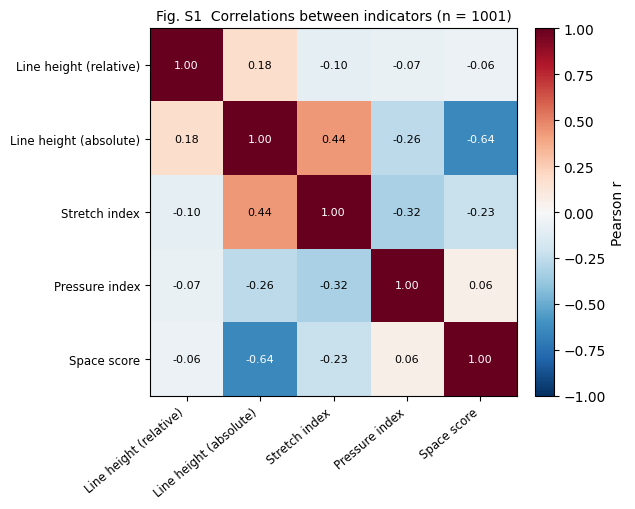

max |r| between different indicators: 0.64 | max VIF: 2.2 (VIF < 5 = acceptable)


In [21]:
# ======================================================================
# B8. Supplementary Table S1 (ranges, outliers) and Fig. S1 (correlations + VIF)
# Raw units, analysis sample. Outliers are counted and reported, not removed.
# Needs only main_sample (A11). If the kernel was restarted, first run A1, A2 and:
#   features_corrected = pd.read_csv(OUT_CSV); then cell A11.
# ======================================================================
X = main_sample[FEATURES].rename(columns=NICE)

s1 = X.describe(percentiles=[.25, .5, .75]).T[['min', '25%', '50%', '75%', 'max', 'mean', 'std']]
s1.columns = ['Min', 'Q1', 'Median', 'Q3', 'Max', 'Mean', 'SD']
s1['Range'] = s1['Max'] - s1['Min']
z = (X - X.mean()) / X.std(ddof=1)
iqr = s1['Q3'] - s1['Q1']
lo, hi = s1['Q1'] - 1.5 * iqr, s1['Q3'] + 1.5 * iqr
s1['z-score outliers (|z|>3)'] = (z.abs() > 3).sum()
s1['IQR outliers'] = ((X < lo) | (X > hi)).sum()
s1['IQR lower bound'], s1['IQR upper bound'] = lo, hi
s1['outlier % (IQR)'] = 100 * s1['IQR outliers'] / len(X)

def vif(df):
    """Variance inflation factor: 1 / (1 - R^2) of each feature regressed on the others."""
    out = {}
    for c in df.columns:
        y = df[c].to_numpy(float)
        A = np.column_stack([np.ones(len(df)), df.drop(columns=c).to_numpy(float)])
        beta, *_ = np.linalg.lstsq(A, y, rcond=None)
        r2 = 1 - ((y - A @ beta) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        out[c] = 1 / (1 - r2)
    return pd.Series(out)
s1['VIF'] = vif(X)
print(f"=== Supplementary Table S1 (n = {len(X)}) ===")
display(s1.round(3))
s1.to_csv(os.path.join(OUT_DIR, 'tableS1_descriptives_outliers.csv'))

corr = X.corr()
fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=40, ha='right', fontsize=8.5)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8.5)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha='center', va='center', fontsize=8,
                color='white' if abs(corr.iloc[i, j]) > 0.6 else 'black')
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Pearson r')
ax.set_title(f'Fig. S1  Correlations between indicators (n = {len(X)})', fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'figS1_correlations.png'), dpi=300); plt.show()
print("max |r| between different indicators:", round(float((corr.abs() - np.eye(len(corr))).max().max()), 2),
      "| max VIF:", round(float(s1['VIF'].max()), 2), "(VIF < 5 = acceptable)")


## B9. Robustness 4: sequences from the same match
(a) Cross-validation with folds split by match vs by sequence. (b) Linear mixed model with a random intercept for match vs the two-way ANOVA. Needs `main_sample` (A11), `table2` (B1) and `make_models` (B3); about 1 minute.

In [22]:
# ======================================================================
# B9. Robustness 4: dependence between sequences from the same match
#   Sequences from one match are not independent (same opponent, same day).
#   (a) Models: 5-fold CV with folds split BY MATCH (no match in both training and
#       validation folds), next to ordinary sequence-level 5-fold CV. Both use all of a
#       team's sequences, class-weighted, scaling inside the pipeline (as Table 4).
#   (b) Statistics: linear mixed model per feature, Team x Outcome (sum-coded) with a
#       random intercept for match, next to the two-way ANOVA p-values of Table 2,
#       checked with cluster-robust OLS (no optimizer involved).
# Needs main_sample (A11), table2 (B1) and make_models (B3). About 1 minute.
# ======================================================================
import warnings as _w
import statsmodels.formula.api as smf
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_score

# ---------------- (a) match-grouped cross-validation ----------------
rows = []
for team in TEAMS:
    d = main_sample[main_sample['team_lost_possession'] == team].reset_index(drop=True)
    X, y, g = d[FEATURES], d['label'].astype(int), d['match_id']
    print(f"{team}: {len(d)} sequences from {g.nunique()} matches "
          f"(median {int(g.value_counts().median())} per match)")
    for name, model in make_models(y, weighted=True).items():
        pipe = make_pipeline(StandardScaler(), clone(model))      # scaler refitted inside every fold
        by_seq = cross_val_score(pipe, X, y, scoring='roc_auc',
                                 cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
        by_match = cross_val_score(pipe, X, y, groups=g, scoring='roc_auc',
                                   cv=StratifiedGroupKFold(5, shuffle=True, random_state=SEED))
        rows.append({'team': team, 'algorithm': name,
                     'CV AUC, folds by sequence': by_seq.mean(), 'SD seq': by_seq.std(ddof=1),
                     'CV AUC, folds by match': by_match.mean(), 'SD match': by_match.std(ddof=1)})
cv_match = pd.DataFrame(rows)
cv_match['difference (match - seq)'] = cv_match['CV AUC, folds by match'] - cv_match['CV AUC, folds by sequence']
print("\n=== (a) Cross-validated ROC AUC: folds by sequence vs folds by match ===")
display(cv_match.round(3))
cv_match.to_csv(os.path.join(OUT_DIR, 'robust_match_grouped_cv.csv'), index=False)

# ---------------- (b) mixed model, random intercept per match ----------------
# statsmodels optimizers can stop at a false solution (match variance = 0 with broken
# standard errors). So every optimizer is tried and the converged fit with the HIGHEST
# REML log-likelihood is kept (= the actual REML estimate).
# Optimizer-free check: ordinary least squares with cluster-robust SEs (clusters = matches).
FORMULA = "z ~ C(team, Sum) * C(outcome, Sum)"

def fit_mixed(dm):
    fits = []
    for method in (None, 'bfgs', 'lbfgs', 'powell', 'nm', 'cg'):   # None = statsmodels default
        with _w.catch_warnings():
            _w.simplefilter('ignore')
            try:
                r = smf.mixedlm(FORMULA, dm, groups=dm['match_id']).fit(reml=True, method=method)
            except Exception:
                continue
        if np.isfinite(r.llf) and np.all(np.isfinite(r.bse_fe)):
            fits.append((bool(r.converged), r.llf, method or 'default', r))
    if not fits:
        raise RuntimeError("no mixed-model fit succeeded")
    fits.sort(key=lambda t: (t[0], t[1]), reverse=True)   # converged first, then highest log-likelihood
    return fits[0][3], fits[0][2]

def effect_name(term):
    return 'Team * Outcome' if ':' in term else ('Team' if 'team' in term else 'Outcome')

dm = main_sample.copy()
dm['team'] = dm['team_lost_possession']
dm['outcome'] = dm['label'].map({0: 'Failure', 1: 'Success'})
clusters = pd.factorize(dm['match_id'])[0]
rows = []
for f in FEATURES:
    dm['z'] = (dm[f] - dm[f].mean()) / dm[f].std(ddof=1)        # z-scale: helps convergence, p unchanged
    fit, method = fit_mixed(dm)
    ols = smf.ols(FORMULA, dm).fit(cov_type='cluster', cov_kwds={'groups': clusters})
    var_match = float(fit.cov_re.iloc[0, 0])
    icc = var_match / (var_match + float(fit.scale))
    for term in fit.fe_params.index:
        if term == 'Intercept':
            continue
        rows.append({'feature': NICE[f], 'effect': effect_name(term),
                     'coef (z units)': float(fit.fe_params[term]),
                     'p mixed model': float(fit.pvalues[term]),
                     'p cluster-robust': float(ols.pvalues[term]),
                     'ICC (match)': icc, 'optimizer': method, 'converged': bool(fit.converged)})
mixed = pd.DataFrame(rows).merge(table2[['feature', 'effect', 'p']].rename(columns={'p': 'p ANOVA'}),
                                 on=['feature', 'effect'], how='left')
for col, lab in (('p ANOVA', 'ANOVA'), ('p mixed model', 'mixed'), ('p cluster-robust', 'cluster')):
    mixed[f'sig .01 {lab}'] = np.where(mixed[col] < ALPHA_BONF, 'yes', 'no')
print("\n=== (b) p-values: two-way ANOVA vs mixed model (random intercept for match) vs cluster-robust OLS ===")
display(mixed[['feature', 'effect', 'p ANOVA', 'p mixed model', 'p cluster-robust',
               'sig .01 ANOVA', 'sig .01 mixed', 'sig .01 cluster',
               'coef (z units)', 'ICC (match)', 'optimizer', 'converged']].round(4))
mixed.to_csv(os.path.join(OUT_DIR, 'robust_mixed_model.csv'), index=False)

print("\nCHECK: all mixed models converged:", 'OK' if mixed['converged'].all() else 'PROBLEM')
agree = (mixed['sig .01 mixed'] == mixed['sig .01 cluster']).all()
print("CHECK: mixed model and cluster-robust OLS agree on significance at .01:",
      'OK' if agree else 'NO, see table')
same = (mixed['sig .01 ANOVA'] == mixed['sig .01 mixed']).all()
print("INFO: same effects significant at .01 in ANOVA and mixed model:", 'yes' if same else 'no, see table')


Barcelona: 515 sequences from 38 matches (median 13 per match)
Real Madrid: 486 sequences from 37 matches (median 13 per match)

=== (a) Cross-validated ROC AUC: folds by sequence vs folds by match ===


,team,algorithm,"CV AUC, folds by sequence",SD seq,"CV AUC, folds by match",SD match,difference (match - seq)
0,Barcelona,XGBoost,0.744,0.010,0.730,0.071,-0.014
1,Barcelona,Random Forest,0.755,0.019,0.751,0.075,-0.005
2,Barcelona,SVM (RBF),0.749,0.045,0.754,0.066,0.006
3,Real Madrid,XGBoost,0.683,0.044,0.669,0.033,-0.015
4,Real Madrid,Random Forest,0.709,0.052,0.716,0.038,0.007
5,Real Madrid,SVM (RBF),0.717,0.050,0.721,0.062,0.004



=== (b) p-values: two-way ANOVA vs mixed model (random intercept for match) vs cluster-robust OLS ===


,feature,effect,p ANOVA,p mixed model,p cluster-robust,sig .01 ANOVA,sig .01 mixed,sig .01 cluster,coef (z units),ICC (match),optimizer,converged
0,Line height (relative),Team,0.0033,0.0175,0.0327,yes,no,no,-0.0951,0.0159,powell,True
1,Line height (relative),Outcome,0.0000,0.0000,0.0000,yes,yes,yes,-0.3846,0.0159,powell,True
2,Line height (relative),Team * Outcome,0.9172,0.8947,0.9238,no,no,no,-0.0050,0.0159,powell,True
3,Line height (absolute),Team,0.0911,0.2060,0.0776,no,no,no,0.0632,0.0828,powell,True
4,Line height (absolute),Outcome,0.0000,0.0000,0.0000,yes,yes,yes,-0.1714,0.0828,powell,True
5,Line height (absolute),Team * Outcome,0.1111,0.1619,0.1465,no,no,no,0.0536,0.0828,powell,True
6,Stretch index,Team,0.1730,0.3140,0.4356,no,no,no,-0.0425,0.0146,powell,True
7,Stretch index,Outcome,0.2343,0.2174,0.3434,no,no,no,0.0488,0.0146,powell,True
8,Stretch index,Team * Outcome,0.7657,0.8166,0.8033,no,no,no,0.0092,0.0146,powell,True
9,Pressure index,Team,0.0000,0.0001,0.0001,yes,yes,yes,0.1761,0.0348,powell,True



CHECK: all mixed models converged: OK
CHECK: mixed model and cluster-robust OLS agree on significance at .01: OK
INFO: same effects significant at .01 in ANOVA and mixed model: no, see table


## C. Figures for the manuscript
Run after B9 (C2 to C4 need `main_sample`, C3 needs `table2` from B1). Each cell saves a PNG (300 dpi) into `OUT_DIR/fig/` 
with the file name used in the LaTeX source: `zones.png` (Fig. 1), `feature_visual.png` (Fig. 2), 
`fig3_interaction.png` (Fig. 3), `figS1_correlations.png` (Fig. S1). Copy that folder next to the .tex file as `fig/`.

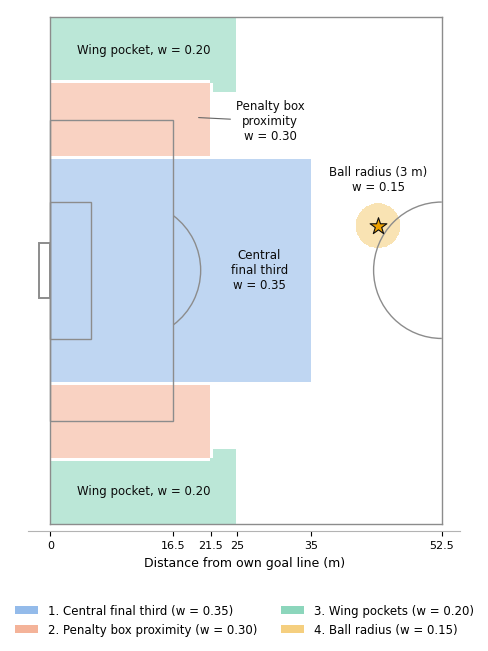

CHECK: every zone visible on the figure: OK


In [23]:
# ======================================================================
# C1. Figure 1: tactical zones of the space score
#   Drawn from ZONES itself (priority order), so the figure always matches the code.
#   Own goal on the LEFT (x = 0), as after normalization. The ball zone moves with the
#   ball; it is drawn for one example ball position.
#   Saves fig/zones.png (the file name used in the LaTeX source).
# ======================================================================
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle, Arc, Patch

FIG_DIR = os.path.join(OUT_DIR, 'fig')
os.makedirs(FIG_DIR, exist_ok=True)
INK, LINE = '#0b0b0b', '0.55'
ZONE_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']        # slot order = ZONES priority order
ZONE_NAMES = {'central_third': 'Central final third', 'penalty_buffer': 'Penalty box proximity',
              'wing_pockets': 'Wing pockets', 'ball_radius': 'Ball radius'}

def draw_pitch(ax, x_max=FIELD_L):
    """Pitch lines in metres, own goal at x = 0."""
    kw = dict(color=LINE, lw=1, zorder=3)
    ax.plot([0, x_max], [0, 0], **kw); ax.plot([0, x_max], [FIELD_W, FIELD_W], **kw)
    ax.plot([0, 0], [0, FIELD_W], **kw)
    if x_max >= FIELD_L:
        ax.plot([FIELD_L, FIELD_L], [0, FIELD_W], **kw)
    ax.plot([FIELD_L / 2] * 2, [0, FIELD_W], **kw)
    for x0, sgn in ((0, 1), (FIELD_L, -1)):
        if x0 > x_max:
            continue
        ax.add_patch(Rectangle((x0, BOX_Y_MIN), sgn * BOX_DEPTH, BOX_Y_MAX - BOX_Y_MIN, fill=False, ec=LINE, lw=1, zorder=3))
        ax.add_patch(Rectangle((x0, FIELD_W / 2 - 9.16), sgn * 5.5, 18.32, fill=False, ec=LINE, lw=1, zorder=3))
        ax.add_patch(Rectangle((x0, FIELD_W / 2 - 3.66), -sgn * 1.5, 7.32, fill=False, ec=LINE, lw=1.4, zorder=3))
        th = (-53, 53) if sgn == 1 else (127, 233)
        ax.add_patch(Arc((x0 + sgn * 11, FIELD_W / 2), 18.3, 18.3, theta1=th[0], theta2=th[1], color=LINE, lw=1, zorder=3))
    th = (90, 270) if x_max < FIELD_L else (0, 360)
    ax.add_patch(Arc((FIELD_L / 2, FIELD_W / 2), 18.3, 18.3, theta1=th[0], theta2=th[1], color=LINE, lw=1, zorder=3))

ball_ex = np.array([44.0, 40.0])                                   # example ball position
X_MAX, STEP = FIELD_L / 2 + 2.5, 0.1
xs, ys = np.arange(0, X_MAX, STEP) + STEP / 2, np.arange(0, FIELD_W, STEP) + STEP / 2
zone_idx = np.full((len(ys), len(xs)), -1)
for j, y in enumerate(ys):
    for i, x in enumerate(xs):
        for k, (_, _, test) in enumerate(ZONES):
            if test((x, y), ball_ex):                              # first match = highest priority
                zone_idx[j, i] = k
                break

# thin white gap where two zones meet, so adjacent fills stay distinguishable
shown = zone_idx.copy()
for d in range(1, 4):
    for axis in (0, 1):
        for sh in (d, -d):
            nb = np.roll(zone_idx, sh, axis=axis)
            shown[(zone_idx >= 0) & (nb >= 0) & (nb != zone_idx) & (zone_idx > nb)] = -1

fig, ax = plt.subplots(figsize=(6.2, 6.6))
ax.imshow(np.ma.masked_less(shown, 0), cmap=ListedColormap(ZONE_COLORS), vmin=-0.5, vmax=3.5,
          alpha=0.30, origin='lower', extent=[0, X_MAX, 0, FIELD_W], interpolation='nearest', zorder=1)
draw_pitch(ax, x_max=FIELD_L / 2)
ax.scatter(*ball_ex, marker='*', s=160, c='#eda100', edgecolor=INK, lw=0.8, zorder=5)

w = {name: wt for name, wt, _ in ZONES}
lab = dict(ha='center', va='center', fontsize=8.5, color=INK, zorder=6)
ax.text(28.0, 34.0, f"Central\nfinal third\nw = {w['central_third']:.2f}", **lab)
ax.annotate(f"Penalty box\nproximity\nw = {w['penalty_buffer']:.2f}", xy=(19.5, 54.5), xytext=(29.5, 54.0),
            arrowprops=dict(arrowstyle='-', color='0.4', lw=0.8), **lab)
ax.text(12.5, 4.4, f"Wing pocket, w = {w['wing_pockets']:.2f}", **lab)
ax.text(12.5, FIELD_W - 4.4, f"Wing pocket, w = {w['wing_pockets']:.2f}", **lab)
ax.text(ball_ex[0], ball_ex[1] + BALL_RADIUS + 3.2, f"Ball radius ({BALL_RADIUS:g} m)\nw = {w['ball_radius']:.2f}", **lab)

ax.set_xlim(-3, X_MAX); ax.set_ylim(-1, FIELD_W + 1); ax.set_aspect('equal')
ax.set_xticks([0, BOX_DEPTH, BOX_DEPTH + 5, 25, 35, FIELD_L / 2])
ax.set_xticklabels(['0', '16.5', '21.5', '25', '35', '52.5'], fontsize=8)
ax.set_yticks([])
ax.set_xlabel('Distance from own goal line (m)', fontsize=9)
for s in ('top', 'right', 'left'):
    ax.spines[s].set_visible(False)
ax.spines['bottom'].set_color('0.7')
ax.legend(handles=[Patch(fc=c, alpha=0.5, label=f"{i + 1}. {ZONE_NAMES[n]} (w = {wt:.2f})")
                   for i, ((n, wt, _), c) in enumerate(zip(ZONES, ZONE_COLORS))],
          loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=8.5, frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'zones.png'), dpi=300, bbox_inches='tight')
plt.show()
counts = {ZONE_NAMES[n]: int((zone_idx == k).sum()) for k, (n, _, _) in enumerate(ZONES)}
print("CHECK: every zone visible on the figure:", 'OK' if all(v > 0 for v in counts.values()) else 'PROBLEM')


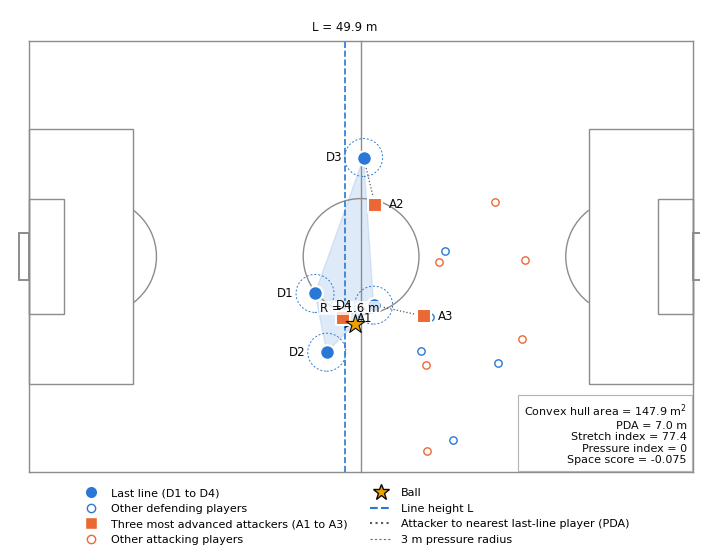

For the caption: Barcelona lost the ball (success); match 1024083, frame 45490; main_sample index 93
CHECK: 4 last-line players, 3 attackers, pressure 0-3: OK


In [24]:
# ======================================================================
# C2. Figure 2: one frame with the features (role labels only, no player names or IDs)
#   Default: the successful Barcelona sequence whose relative line height is closest to the
#   median of successful Barcelona sequences, at the frame the ball first entered the own half.
#   Set EX_INDEX (a row index of main_sample) and/or EX_FRAME to choose another frame.
#   Saves fig/feature_visual.png (the file name used in the LaTeX source).
#   Needs A1-A8 and A11 (main_sample); C1 for draw_pitch.
# ======================================================================
from matplotlib.patches import Polygon, Circle
from matplotlib.lines import Line2D

EX_TEAM, EX_LABEL = 'Barcelona', 1
EX_INDEX, EX_FRAME = None, None
BLUE, ORANGE = '#2a78d6', '#eb6834'

def draw_feature_frame(ax, D, A, ball, ff):
    """Normalized frame (own goal at x = 0) with last line, three most advanced attackers and features."""
    draw_pitch(ax)
    B4 = D[np.argsort(D[:, 0])[:4]]          # D1 = deepest
    A3 = A[np.argsort(A[:, 0])[:3]]          # A1 = most advanced
    others_D = np.array([p for p in D if not np.isclose(B4, p).all(1).any()])
    others_A = np.array([p for p in A if not np.isclose(A3, p).all(1).any()])
    try:
        hv = ConvexHull(B4).vertices
        ax.add_patch(Polygon(B4[hv], closed=True, fc=BLUE, alpha=0.15, ec=BLUE, lw=1, zorder=2))
    except Exception:
        pass
    for p in B4:                                                         # 3 m pressure radius
        ax.add_patch(Circle(p, PRESS_R, fill=False, ec=BLUE, lw=0.7, ls=(0, (2, 2)), zorder=2))
    for a in A3:                                                         # PDA: attacker -> nearest last-line player
        d = B4[np.argmin(np.linalg.norm(B4 - a, axis=1))]
        ax.plot([a[0], d[0]], [a[1], d[1]], color='0.35', lw=0.9, ls=':', zorder=3)
    L = ff['line_height_abs']
    ax.plot([L, L], [0, FIELD_W], color=BLUE, lw=1.2, ls='--', zorder=3)
    ax.text(L, FIELD_W + 1.2, f"L = {L:.1f} m", ha='center', va='bottom', fontsize=8.5, color=INK)
    ax.annotate('', xy=(ball[0], ball[1]), xytext=(L, ball[1]),
                arrowprops=dict(arrowstyle='->', color=INK, lw=1), zorder=4)
    ax.text((L + ball[0]) / 2, ball[1] + 1.6, f"R = {ff['line_height_rel_ball']:.1f} m",
            ha='center', va='bottom', fontsize=8.5, color=INK, zorder=6,
            bbox=dict(fc='white', ec='none', alpha=0.8, pad=0.5))
    if len(others_D):
        ax.scatter(others_D[:, 0], others_D[:, 1], s=28, c='white', edgecolor=BLUE, lw=1, zorder=4)
    if len(others_A):
        ax.scatter(others_A[:, 0], others_A[:, 1], s=28, c='white', edgecolor=ORANGE, lw=1, zorder=4)
    ax.scatter(B4[:, 0], B4[:, 1], s=110, c=BLUE, edgecolor='white', lw=1.5, zorder=5)
    ax.scatter(A3[:, 0], A3[:, 1], s=110, c=ORANGE, edgecolor='white', lw=1.5, marker='s', zorder=5)
    for k, p in enumerate(B4):
        ax.text(p[0] - 3.4, p[1], f"D{k + 1}", ha='right', va='center', fontsize=8.5, color=INK, zorder=6)
    for k, p in enumerate(A3):
        ax.text(p[0] + 2.2, p[1], f"A{k + 1}", ha='left', va='center', fontsize=8.5, color=INK, zorder=6)
    ax.scatter(*ball, marker='*', s=200, c='#eda100', edgecolor=INK, lw=0.8, zorder=7)
    txt = (f"Convex hull area = {ff['hull_area']:.1f} m$^2$\nPDA = {ff['pda']:.1f} m\n"
           f"Stretch index = {ff['stretch_index']:.1f}\nPressure index = {ff['pressure_index']}\n"
           f"Space score = {ff['space_score']:.3f}")
    ax.text(FIELD_L - 1, 1, txt, ha='right', va='bottom', fontsize=8, color=INK, zorder=8,
            bbox=dict(fc='white', ec='0.7', lw=0.8, pad=4))
    ax.set_xlim(-3, FIELD_L + 1); ax.set_ylim(-1, FIELD_W + 5); ax.set_aspect('equal'); ax.axis('off')
    handles = [Line2D([], [], marker='o', ls='', ms=9, mfc=BLUE, mec='white', label='Last line (D1 to D4)'),
               Line2D([], [], marker='o', ls='', ms=6, mfc='white', mec=BLUE, label='Other defending players'),
               Line2D([], [], marker='s', ls='', ms=9, mfc=ORANGE, mec='white', label='Three most advanced attackers (A1 to A3)'),
               Line2D([], [], marker='o', ls='', ms=6, mfc='white', mec=ORANGE, label='Other attacking players'),
               Line2D([], [], marker='*', ls='', ms=12, mfc='#eda100', mec=INK, label='Ball'),
               Line2D([], [], color=BLUE, ls='--', label='Line height L'),
               Line2D([], [], color='0.35', ls=':', label='Attacker to nearest last-line player (PDA)'),
               Line2D([], [], color=BLUE, ls=(0, (2, 2)), lw=0.8, label='3 m pressure radius')]
    ax.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=2, fontsize=8, frameon=False)

if 'main_sample' in globals():
    if EX_INDEX is None:
        cand = main_sample[(main_sample['team_lost_possession'] == EX_TEAM) & (main_sample['label'] == EX_LABEL)
                           & main_sample['frame_entry_own_half'].notna()]
        med = cand['line_height_rel_ball_mean'].median()
        EX_INDEX = (cand['line_height_rel_ball_mean'] - med).abs().idxmin()
    r = main_sample.loc[EX_INDEX]
    _events, _tracking, _match = load_match(r['match_id'])
    trk_ex = build_tracking(_tracking, _match)
    hdl_ex = home_defends_left(trk_ex)
    side_ex = 'h' if r['team_lost_possession'] == r['home_team'] else 'a'
    f_ex = int(EX_FRAME if EX_FRAME is not None else r['frame_entry_own_half'])
    st = frame_state(trk_ex, f_ex, side_ex, int(r['period']), hdl_ex)
    if st is None:                                            # no tracking on that frame: use the loss frame
        f_ex = int(r['frame_loss'])
        st = frame_state(trk_ex, f_ex, side_ex, int(r['period']), hdl_ex)
    D_ex, A_ex, ball_ex2 = st
    ff_ex = frame_features(D_ex, A_ex, ball_ex2)
    fig, ax = plt.subplots(figsize=(7.2, 6.0))
    draw_feature_frame(ax, D_ex, A_ex, ball_ex2, ff_ex)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, 'feature_visual.png'), dpi=300, bbox_inches='tight')
    plt.show()
    print(f"For the caption: {r['team_lost_possession']} lost the ball ({'success' if r['label'] == 1 else 'failure'}); "
          f"match {r['match_id']}, frame {f_ex}; main_sample index {EX_INDEX}")
    print("CHECK: 4 last-line players, 3 attackers, pressure 0-3:",
          'OK' if ff_ex is not None and 0 <= ff_ex['pressure_index'] <= 3 else 'PROBLEM')


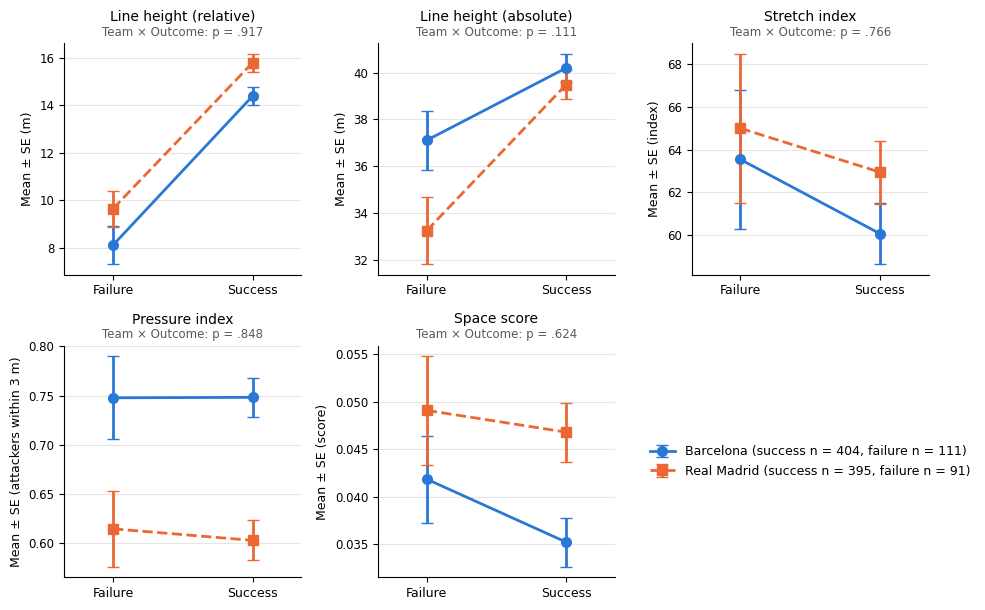

In [25]:
# ======================================================================
# C3. Figure 3: mean +/- SE of each indicator by team and outcome
#   Interaction p from Table 2 (B1) in each panel. No figure number inside the image.
#   Saves fig/fig3_interaction.png. Needs main_sample (A11) and table2 (B1).
# ======================================================================
TEAM_STYLE = {'Barcelona': dict(color='#2a78d6', ls='-', marker='o'),
              'Real Madrid': dict(color='#eb6834', ls='--', marker='s')}
UNITS = {'line_height_rel_ball_mean': 'm', 'line_height_abs_mean': 'm', 'stretch_index_mean': 'index',
         'pressure_index_mean': 'attackers within 3 m', 'space_score_mean': 'score'}

fig, axs = plt.subplots(2, 3, figsize=(10, 6.2))
for ax, f in zip(axs.flat, FEATURES):
    for team in TEAMS:
        g = (main_sample[main_sample['team_lost_possession'] == team]
             .groupby('label')[f].agg(['mean', 'sem']).reindex([0, 1]))
        st = TEAM_STYLE[team]
        ax.errorbar([0, 1], g['mean'], yerr=g['sem'], color=st['color'], ls=st['ls'], marker=st['marker'],
                    ms=7, lw=2, capsize=4, label=team)
    p_int = table2.loc[(table2['feature'] == NICE[f]) & (table2['effect'] == 'Team * Outcome'), 'p'].iloc[0]
    ax.text(0.5, 1.02, f"Team × Outcome: p = {p_int:.3f}".replace('0.', '.'), transform=ax.transAxes,
            fontsize=8.5, ha='center', va='bottom', color='0.35')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Failure', 'Success'], fontsize=9); ax.set_xlim(-0.35, 1.35)
    ax.set_title(NICE[f], fontsize=10, pad=16)
    ax.set_ylabel(f"Mean ± SE ({UNITS[f]})", fontsize=9)
    ax.tick_params(axis='y', labelsize=8.5)
    ax.grid(axis='y', color='0.9', lw=0.8); ax.set_axisbelow(True)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
axs.flat[-1].axis('off')
n = main_sample.groupby(['team_lost_possession', 'label']).size()
handles, _ = axs.flat[0].get_legend_handles_labels()
axs.flat[-1].legend(handles, [f"{t} (success n = {n[(t, 1)]}, failure n = {n[(t, 0)]})" for t in TEAMS],
                    loc='center', fontsize=9, frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig3_interaction.png'), dpi=300, bbox_inches='tight')
plt.show()


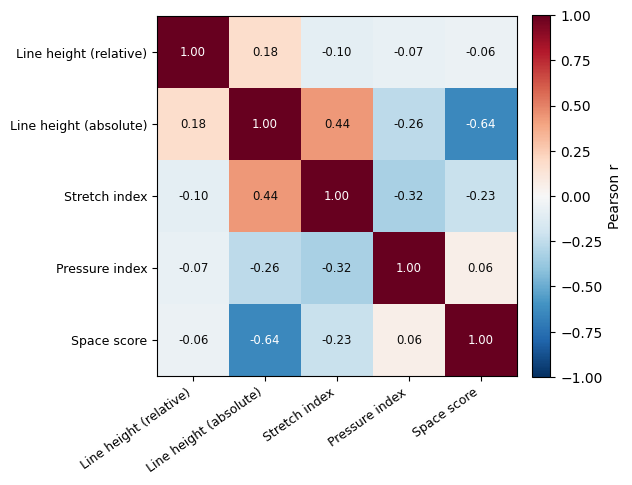

largest |r| = 0.64 (('Line height (absolute)', 'Space score'))  -> caption of Fig. S1


In [26]:
# ======================================================================
# C4. Supplementary Figure S1: correlations between the five indicators (analysis sample)
#   Same numbers as B8; no figure number inside the image. Saves fig/figS1_correlations.png.
# ======================================================================
Xc = main_sample[FEATURES].rename(columns=NICE)
corr = Xc.corr()
fig, ax = plt.subplots(figsize=(6.0, 5.0))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=35, ha='right', fontsize=9)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=9)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha='center', va='center', fontsize=8.5,
                color='white' if abs(corr.iloc[i, j]) > 0.6 else INK)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Pearson r')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'figS1_correlations.png'), dpi=300, bbox_inches='tight')
plt.show()
off = corr.where(~np.eye(len(corr), dtype=bool)).abs()
print(f"largest |r| = {off.max().max():.2f} ({off.stack().idxmax()})  -> caption of Fig. S1")


In [27]:
print(os.path.join(OUT_DIR, 'fig'))
print(sorted(os.listdir(os.path.join(OUT_DIR, 'fig'))))

/home/s_dash/workspace7/Defense_line_analysis/Defense_line/Barcelona_tracking_excels/combined_outputs/fig
['feature_visual.png', 'fig3_interaction.png', 'figS1_correlations.png', 'zones.png']


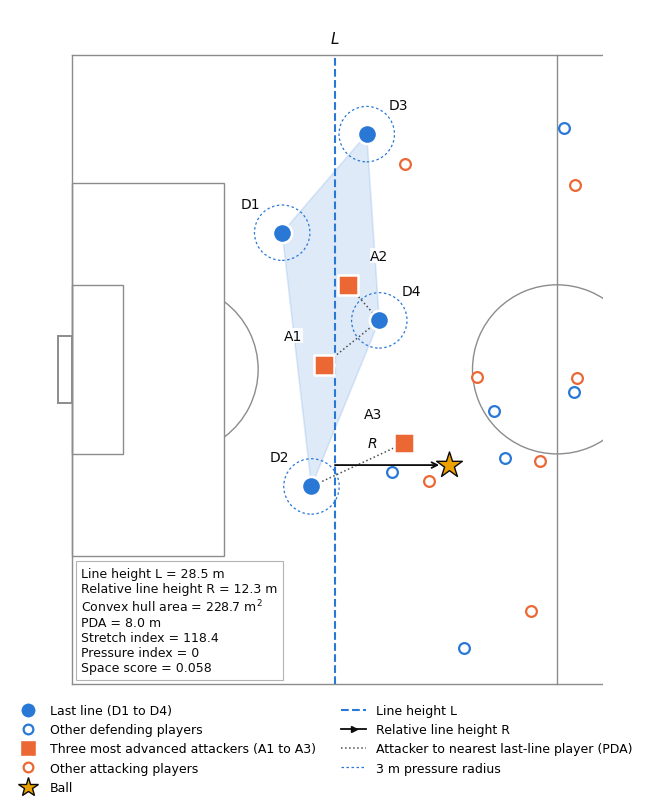

For the caption: Barcelona lost the ball (success); match 1365684, frame 23943; main_sample index 1932
CHECK: 4 last-line players, 3 attackers, pressure 0-3: OK


In [28]:
# ======================================================================
# C2. Figure 2: one frame with the features (role labels only, no player names or IDs)
#   Frame choice (automatic): among the successful Barcelona sequences closest to the median
#   relative line height, the first frame of the defending phase that is clear to read:
#   ball inside the own half (20-45 m from goal), the 4 last-line players, 3 attackers and the
#   ball at least MIN_GAP m apart, and R closest to the sequence mean.
#   To fix the frame yourself: set EX_INDEX (row index of main_sample) and EX_FRAME.
#   The view is cropped to the part of the pitch that matters, so the markers are larger.
#   Saves fig/feature_visual.png. Needs A1-A8, A11 (main_sample) and C1 (draw_pitch).
# ======================================================================
from matplotlib.patches import Polygon, Circle
from matplotlib.lines import Line2D

EX_TEAM, EX_LABEL = 'Barcelona', 1
EX_INDEX, EX_FRAME = None, None
N_CANDIDATES, MIN_GAP = 15, 4.0
BLUE, ORANGE, BALL_C = '#2a78d6', '#eb6834', '#eda100'

def split_roles(D, A):
    B4 = D[np.argsort(D[:, 0])[:4]]                      # D1 = deepest
    A3 = A[np.argsort(A[:, 0])[:3]]                      # A1 = most advanced
    oD = np.array([p for p in D if not np.isclose(B4, p).all(1).any()]).reshape(-1, 2)
    oA = np.array([p for p in A if not np.isclose(A3, p).all(1).any()]).reshape(-1, 2)
    return B4, A3, oD, oA

def frame_quality(D, A, ball, ff, r_target):
    """Lower is better; inf = not usable for the figure."""
    if ff is None:
        return np.inf
    B4, A3, _, _ = split_roles(D, A)
    P = np.vstack([B4, A3, np.asarray(ball)[None, :]])
    gaps = np.linalg.norm(P[:, None] - P[None, :], axis=2)[np.triu_indices(len(P), 1)]
    if gaps.min() < MIN_GAP or not (20 <= ball[0] <= 45):
        return np.inf
    return abs(ff['line_height_rel_ball'] - r_target)

def place_label(ax, x, y, text, obstacles, placed, d=2.4, char_w=0.8, **kw):
    """Put a label on the side of (x, y) that is furthest from markers and other labels."""
    w, h = char_w * len(text), 1.6
    opts = [(-d, 0, 'right', 'center', -d - w / 2, 0), (d, 0, 'left', 'center', d + w / 2, 0),
            (0, d, 'center', 'bottom', 0, d + h / 2), (0, -d, 'center', 'top', 0, -d - h / 2),
            (-d, d, 'right', 'bottom', -d - w / 2, d + h / 2), (d, d, 'left', 'bottom', d + w / 2, d + h / 2),
            (-d, -d, 'right', 'top', -d - w / 2, -d - h / 2), (d, -d, 'left', 'top', d + w / 2, -d - h / 2)]
    pts = np.array(list(obstacles) + list(placed)).reshape(-1, 2)
    best = max(opts, key=lambda o: np.min(np.linalg.norm(pts - [x + o[4], y + o[5]], axis=1)))
    ax.text(x + best[0], y + best[1], text, ha=best[2], va=best[3], fontsize=10, color=INK, zorder=9,
            bbox=dict(fc='white', ec='none', alpha=0.85, pad=0.4), **kw)
    placed.append([x + best[4], y + best[5]])

def draw_feature_frame(ax, D, A, ball, ff):
    """Normalized frame (own goal at x = 0), cropped to the relevant part of the pitch."""
    ball = np.asarray(ball, float)
    B4, A3, oD, oA = split_roles(D, A)
    key = np.vstack([B4, A3, ball[None, :]])
    x_max = float(np.clip(key[:, 0].max() + 12, FIELD_L / 2 + 5, FIELD_L))
    draw_pitch(ax)                                                       # full pitch; the axis limits crop it
    try:
        hv = ConvexHull(B4).vertices
        ax.add_patch(Polygon(B4[hv], closed=True, fc=BLUE, alpha=0.15, ec=BLUE, lw=1.2, zorder=2))
    except Exception:
        pass
    for p in B4:                                                         # 3 m pressure radius
        ax.add_patch(Circle(p, PRESS_R, fill=False, ec=BLUE, lw=0.9, ls=(0, (2, 2)), zorder=2))
    for a in A3:                                                         # PDA segments
        d = B4[np.argmin(np.linalg.norm(B4 - a, axis=1))]
        ax.plot([a[0], d[0]], [a[1], d[1]], color='0.3', lw=1.1, ls=':', zorder=3)
    L, R = ff['line_height_abs'], ff['line_height_rel_ball']
    ax.plot([L, L], [0, FIELD_W], color=BLUE, lw=1.5, ls='--', zorder=3)
    ax.text(L, FIELD_W + 1.0, 'L', ha='center', va='bottom', fontsize=11, color=INK, style='italic')
    ax.annotate('', xy=(ball[0], ball[1]), xytext=(L, ball[1]),
                arrowprops=dict(arrowstyle='->', color=INK, lw=1.3, shrinkA=0, shrinkB=7), zorder=4)
    vis = lambda P: P[P[:, 0] <= x_max] if len(P) else P
    if len(oD):
        ax.scatter(oD[:, 0], oD[:, 1], s=60, c='white', edgecolor=BLUE, lw=1.6, zorder=4)
    if len(oA):
        ax.scatter(oA[:, 0], oA[:, 1], s=60, c='white', edgecolor=ORANGE, lw=1.6, zorder=4)
    ax.scatter(B4[:, 0], B4[:, 1], s=190, c=BLUE, edgecolor='white', lw=1.8, zorder=5)
    ax.scatter(A3[:, 0], A3[:, 1], s=190, c=ORANGE, edgecolor='white', lw=1.8, marker='s', zorder=5)
    ax.scatter(*ball, marker='*', s=380, c=BALL_C, edgecolor=INK, lw=1, zorder=7)
    obstacles = np.vstack([key] + [P for P in (vis(oD), vis(oA)) if len(P)])
    placed = []
    for k, p in enumerate(B4):
        place_label(ax, *p, f"D{k + 1}", obstacles, placed)
    for k, p in enumerate(A3):
        place_label(ax, *p, f"A{k + 1}", obstacles, placed)
    place_label(ax, (L + ball[0]) / 2, ball[1], 'R', obstacles, placed, d=1.6, style='italic')
    txt = (f"Line height L = {L:.1f} m\nRelative line height R = {R:.1f} m\n"
           f"Convex hull area = {ff['hull_area']:.1f} m$^2$\nPDA = {ff['pda']:.1f} m\n"
           f"Stretch index = {ff['stretch_index']:.1f}\nPressure index = {ff['pressure_index']}\n"
           f"Space score = {ff['space_score']:.3f}")
    bw, bh = 30.0, 19.0                                                  # approximate box size (m)
    corners = {'lower right': (x_max - bw, 0), 'upper right': (x_max - bw, FIELD_W - bh),
               'lower left': (0, 0), 'upper left': (0, FIELD_W - bh)}
    allP = np.vstack([key] + [P for P in (vis(oD), vis(oA)) if len(P)])
    def n_inside(c):
        x0, y0 = corners[c]
        return int(((allP[:, 0] >= x0) & (allP[:, 0] <= x0 + bw) & (allP[:, 1] >= y0) & (allP[:, 1] <= y0 + bh)).sum())
    corner = min(corners, key=n_inside)
    ha, va = ('right' if 'right' in corner else 'left'), ('bottom' if 'lower' in corner else 'top')
    ax.text(x_max - 1 if ha == 'right' else 1, 1 if va == 'bottom' else FIELD_W - 1, txt, ha=ha, va=va,
            fontsize=9, color=INK, zorder=10, bbox=dict(fc='white', ec='0.7', lw=0.8, pad=4))
    ax.set_xlim(-3, x_max); ax.set_ylim(-1, FIELD_W + 5); ax.set_aspect('equal'); ax.axis('off')
    handles = [Line2D([], [], marker='o', ls='', ms=11, mfc=BLUE, mec='white', label='Last line (D1 to D4)'),
               Line2D([], [], marker='o', ls='', ms=7, mfc='white', mec=BLUE, mew=1.6, label='Other defending players'),
               Line2D([], [], marker='s', ls='', ms=11, mfc=ORANGE, mec='white', label='Three most advanced attackers (A1 to A3)'),
               Line2D([], [], marker='o', ls='', ms=7, mfc='white', mec=ORANGE, mew=1.6, label='Other attacking players'),
               Line2D([], [], marker='*', ls='', ms=15, mfc=BALL_C, mec=INK, label='Ball'),
               Line2D([], [], color=BLUE, ls='--', lw=1.5, label='Line height L'),
               Line2D([], [], color=INK, lw=1.3, marker='>', ms=5, label='Relative line height R'),
               Line2D([], [], color='0.3', ls=':', lw=1.1, label='Attacker to nearest last-line player (PDA)'),
               Line2D([], [], color=BLUE, ls=(0, (2, 2)), lw=0.9, label='3 m pressure radius')]
    ax.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=2, fontsize=9, frameon=False)

if 'main_sample' in globals():
    if EX_INDEX is not None:
        order = [EX_INDEX]
    else:
        cand = main_sample[(main_sample['team_lost_possession'] == EX_TEAM) & (main_sample['label'] == EX_LABEL)]
        med = cand['line_height_rel_ball_mean'].median()
        order = (cand['line_height_rel_ball_mean'] - med).abs().sort_values().index[:N_CANDIDATES]
    cache, chosen = {}, None
    for idx in order:
        r = main_sample.loc[idx]
        if r['match_id'] not in cache:
            _events, _tracking, _match = load_match(r['match_id'])
            _trk = build_tracking(_tracking, _match)
            cache[r['match_id']] = (_trk, home_defends_left(_trk))
        trk_ex, hdl_ex = cache[r['match_id']]
        side_ex = 'h' if r['team_lost_possession'] == r['home_team'] else 'a'
        if EX_FRAME is not None:
            st = frame_state(trk_ex, int(EX_FRAME), side_ex, int(r['period']), hdl_ex)
            chosen = (idx, int(EX_FRAME), st, frame_features(*st))
            break
        f_hi = int(min(r['frame_feature_end'], r['frame_last_event'] + 1))
        best = (np.inf, None, None, None)
        for f in range(int(r['frame_loss']), f_hi, 2):
            st = frame_state(trk_ex, f, side_ex, int(r['period']), hdl_ex)
            if st is None:
                continue
            ff = frame_features(*st)
            q = frame_quality(*st, ff, r['line_height_rel_ball_mean'])
            if q < best[0]:
                best = (q, f, st, ff)
        if best[1] is not None:
            chosen = (idx, best[1], best[2], best[3])
            break
    if chosen is None:
        raise RuntimeError("No clear frame found: lower MIN_GAP or raise N_CANDIDATES.")
    idx, f_ex, (D_ex, A_ex, ball_fig), ff_ex = chosen
    fig, ax = plt.subplots(figsize=(7.0, 8.2))
    draw_feature_frame(ax, D_ex, A_ex, ball_fig, ff_ex)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, 'feature_visual.png'), dpi=300, bbox_inches='tight')
    plt.show()
    r = main_sample.loc[idx]
    print(f"For the caption: {r['team_lost_possession']} lost the ball ({'success' if r['label'] == 1 else 'failure'}); "
          f"match {r['match_id']}, frame {f_ex}; main_sample index {idx}")
    print("CHECK: 4 last-line players, 3 attackers, pressure 0-3:",
          'OK' if ff_ex is not None and 0 <= ff_ex['pressure_index'] <= 3 else 'PROBLEM')

In [29]:
# 1. Software versions: prints the finished LaTeX sentences to paste into the manuscript
import platform, importlib
v = {}
for mod in ('sklearn', 'xgboost', 'shap', 'pingouin', 'statsmodels', 'scipy', 'pandas', 'numpy', 'matplotlib'):
    try:
        v[mod] = importlib.import_module(mod).__version__
    except ImportError:
        v[mod] = 'NOT INSTALLED'
py = platform.python_version()
print("Python", py, v)

print("\n--- Statistical Analysis: replace the pingouin sentence ---")
print(f"\\textcolor{{red}}{{This analysis was performed using the Python package \\texttt{{pingouin}} (v{v['pingouin']}); "
      f"confidence intervals were computed with \\texttt{{SciPy}} (v{v['scipy']}).}}")
print("\n--- End of Machine Learning section: replace the 'All analyses were implemented...' sentence ---")
print(f"\\textcolor{{red}}{{All analyses were implemented in Python {py} using \\texttt{{scikit-learn}} (v{v['sklearn']}) "
      f"for machine learning algorithms, \\texttt{{XGBoost}} (v{v['xgboost']}) for gradient boosting, and \\texttt{{SHAP}} "
      f"(v{v['shap']}) for model interpretability; mixed-effects and cluster-robust models used \\texttt{{statsmodels}} "
      f"(v{v['statsmodels']}). Data were handled with \\texttt{{pandas}} (v{v['pandas']}) and \\texttt{{NumPy}} "
      f"(v{v['numpy']}), and figures were produced with \\texttt{{matplotlib}} (v{v['matplotlib']}).}}")

# 2. 'Penalty Won' check (the StatsBomb v4.0.0 spec records this as Foul Won with penalty = TRUE)
counts = {}
for d in list_matches():
    f = os.path.join(DATA_DIR, d, 'events.csv')
    if os.path.exists(f):
        et = pd.read_csv(f, usecols=['event_type'])['event_type']
        for k in ('Penalty Won', 'Foul Won', 'Shot', 'Own Goal Against'):
            counts[k] = counts.get(k, 0) + int((et == k).sum())
print("\nEvent counts, all matches:", counts)

Python 3.10.15 {'sklearn': '1.7.2', 'xgboost': '3.2.0', 'shap': '0.49.1', 'pingouin': '0.6.1', 'statsmodels': '0.15.0', 'scipy': '1.15.3', 'pandas': '2.3.3', 'numpy': '2.2.6', 'matplotlib': '3.10.9'}

--- Statistical Analysis: replace the pingouin sentence ---
\textcolor{red}{This analysis was performed using the Python package \texttt{pingouin} (v0.6.1); confidence intervals were computed with \texttt{SciPy} (v1.15.3).}

--- End of Machine Learning section: replace the 'All analyses were implemented...' sentence ---
\textcolor{red}{All analyses were implemented in Python 3.10.15 using \texttt{scikit-learn} (v1.7.2) for machine learning algorithms, \texttt{XGBoost} (v3.2.0) for gradient boosting, and \texttt{SHAP} (v0.49.1) for model interpretability; mixed-effects and cluster-robust models used \texttt{statsmodels} (v0.15.0). Data were handled with \texttt{pandas} (v2.3.3) and \texttt{NumPy} (v2.2.6), and figures were produced with \texttt{matplotlib} (v3.10.9).}

Event counts, all ma